# Hoàn thiện biểu đồ EDA theo Moscow

Notebook chứa mã phân tích theo đúng thứ tự từ các file nguồn trong `src/`. Chạy với kernel của `.venv` tại repo. Các bước có thể đọc toàn bộ raw và ghi vào `outputs/`; kiểm tra phạm vi và quy ước thời gian của từng phần trước khi diễn giải. Mã cũ dùng UTC hoặc mẫu là phương pháp cũ, chưa được coi là kết quả Moscow/toàn bộ khách hàng. Script nguồn vẫn được giữ để đối chiếu.

In [1]:
from pathlib import Path
import sys
import time
import pandas as pd
from IPython.display import display, Image, SVG, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'src/scripts'))
sys.path.insert(0, str(ROOT / 'src/mbd_mini_eda_fixes'))
def show_generated_results(started_ns, source):
    changed = sorted((p for base in (ROOT / 'outputs', ROOT / 'docs') if base.exists() for p in base.rglob('*') if p.is_file() and p.stat().st_mtime_ns >= started_ns), key=lambda p: p.as_posix())
    display(Markdown(f'### Kết quả: `{source}`'))
    if not changed:
        display(Markdown('Không có file kết quả mới từ phần này.'))
        return
    images = [p for p in changed if p.suffix.lower() in ('.png', '.jpg', '.jpeg', '.svg')]
    png_stems = {p.with_suffix('') for p in images if p.suffix.lower() == '.png'}
    for p in images:
        if p.suffix.lower() == '.svg' and p.with_suffix('') in png_stems:
            continue
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}**'))
        display(SVG(filename=str(p)) if p.suffix.lower() == '.svg' else Image(filename=str(p)))
    tables = [p for p in changed if p.suffix.lower() == '.csv']
    for p in tables:
        display(Markdown(f'**{p.relative_to(ROOT).as_posix()}** — 5 dòng đầu'))
        try:
            display(pd.read_csv(p, nrows=5))
        except Exception as exc:
            display(Markdown(f'Không đọc được bảng: `{type(exc).__name__}: {exc}`'))
    others = [p.relative_to(ROOT).as_posix() for p in changed if p not in images and p not in tables]
    if others:
        display(Markdown('File kết quả khác: ' + ', '.join(f'`{p}`' for p in others)))

## Complete Eda Figures Moscow

Nguồn: `src/scripts/complete_eda_figures_moscow.py`. Chạy các ô của phần này theo thứ tự.

In [2]:
__file__ = str(ROOT / 'src/scripts/complete_eda_figures_moscow.py')
sys.argv = [__file__]
__eda_started_ns = time.time_ns()
__name__ = '__main__'
__package__ = None


In [3]:
"""Full-population monthly EDA figures; no horizon/model or causal claims.

Reuse the validated Moscow monthly panel; raw-source feature extensions are
tracked separately, never silently represented by monthly proxies.
"""
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parents[2]
BASE = ROOT / 'outputs/full_population_temporal_eda_20261118'
OUT = ROOT / 'outputs/eda_figures_moscow'
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 130,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = ['#2463a6', '#d4772b']
INDEX = []


def publish(name, fig, data, title, construction, meaning, insight, limits):
    fig.suptitle(title, fontsize=14, fontweight='bold')
    fig.text(.01, .012, 'Moscow · toàn bộ khách · nhãn theo tháng · liên hệ mô tả', fontsize=8)
    fig.tight_layout(rect=(0, .045, 1, .94))
    for ext in ['png', 'svg']:
        fig.savefig(OUT / f'{name}.{ext}', bbox_inches='tight')
    plt.close(fig)
    data.to_csv(OUT / f'{name}.csv', index=False)
    (OUT / f'{name}.md').write_text(
        f'# {title}\n\n![{title}](<{(OUT / f"{name}.png").as_posix()}>)\n\n'
        f'## Hình thể hiện gì\n\n{meaning}\n\n'
        f'## Cách dựng\n\n{construction}\n\n'
        f'## Ý nghĩa và insight\n\n{insight}\n\n'
        f'## Giới hạn\n\n{limits}\n', encoding='utf-8')
    INDEX.append({'figure': name, 'title': title, 'data': f'{name}.csv', 'explanation': f'{name}.md'})
    print('Saved', name, flush=True)


def load():
    manifest = json.loads((BASE / 'manifest.json').read_text(encoding='utf-8'))
    assert manifest['timezone'] == 'Europe/Moscow'
    assert all(json.loads((BASE / 'validation.json').read_text()).values())
    p = pd.read_parquet(BASE / 'all_customer_months.parquet')
    p['month'] = pd.to_datetime(p.month)
    labels = pd.read_parquet(BASE / 'labels_any.parquet')
    labels['month'] = pd.to_datetime(labels.month)
    ids = np.sort(labels.client_id.unique())
    months = pd.date_range(p.month.min(), p.month.max(), freq='MS')
    assert len(ids) == 100224 and labels.month.nunique() == 12
    assert len(labels) == len(ids) * 12
    assert not p.duplicated(['client_id', 'month']).any()
    assert p.groupby('month').size().eq(len(ids)).all()
    # Dense customer x month matrices are small; preserve every customer.
    matrices = {}
    for s in ['trx', 'geo', 'dialog']:
        a = p.pivot(index='client_id', columns='month', values=f'{s}_events').reindex(index=ids, columns=months).to_numpy(dtype=float, copy=True)
        av = p.groupby('month')[f'{s}_available'].first().reindex(months).to_numpy(bool)
        a[:, ~av] = np.nan
        matrices[s] = a
    a = p.pivot(index='client_id', columns='month', values='amount11').reindex(index=ids, columns=months).to_numpy(dtype=float, copy=True)
    a[:, ~np.isfinite(matrices['trx']).any(axis=0)] = np.nan
    matrices['amount11'] = a
    y = labels.pivot(index='client_id', columns='month', values='y').reindex(index=ids, columns=months).to_numpy(dtype=float, copy=True)
    return ids, months, matrices, y

In [4]:
def event_studies(ids, months, arrays, y):
    anchors = np.where(np.isfinite(y).any(axis=0))[0]
    all_rows = []
    for metric, a in arrays.items():
        for t in anchors:
            # Baseline uses only complete source months BEFORE relative month -3.
            hist = a[:, :max(0, t-3)].copy()
            if hist.shape[1]:
                valid_months = np.isfinite(hist).sum(axis=1)
                baseline = np.full(len(ids), np.nan)
                eligible = valid_months >= 3
                if eligible.any():
                    baseline[eligible] = np.median(hist[eligible][:, np.isfinite(hist).any(axis=0)], axis=1)
                seen = np.nansum(hist, axis=1) > 0
            else:
                baseline = np.full(len(ids), np.nan)
                eligible = np.zeros(len(ids), bool)
                seen = eligible.copy()
            for lag in range(-3, 4):
                j = t + lag
                v = a[:, j] if 0 <= j < a.shape[1] else np.full(len(ids), np.nan)
                for purchase in [0, 1]:
                    mask = y[:, t] == purchase
                    good = mask & np.isfinite(v)
                    bg = good & eligible
                    delta = v[bg] - baseline[bg]
                    tol = 1e-6 * np.maximum(1, np.abs(baseline[bg]))
                    all_rows.append(dict(metric=metric, anchor=str(months[t].date()), lag=lag,
                        purchase=purchase, population=int(mask.sum()), observed=int(good.sum()),
                        unavailable=int((mask & ~np.isfinite(v)).sum()),
                        mean=float(v[good].mean()) if good.any() else np.nan,
                        median=float(np.median(v[good])) if good.any() else np.nan,
                        baseline_eligible=int(bg.sum()), baseline_insufficient=int((mask & ~eligible).sum()),
                        baseline_unseen=int((mask & eligible & ~seen).sum()),
                        baseline_zero=int((bg & (baseline == 0)).sum()),
                        delta_mean=float(delta.mean()) if len(delta) else np.nan,
                        increase=float((delta > tol).mean()) if len(delta) else np.nan,
                        decrease=float((delta < -tol).mean()) if len(delta) else np.nan,
                        unchanged=float((np.abs(delta) <= tol).mean()) if len(delta) else np.nan))
    d = pd.DataFrame(all_rows)
    assert (d.observed + d.unavailable == d.population).all()
    for metric in arrays:
        g = d[d.metric == metric]
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        for purchase, color in zip([0, 1], COLORS):
            label = 'Mua tháng neo' if purchase else 'Không mua tháng neo'
            z = g[g.purchase == purchase].groupby('lag')[['mean', 'median', 'observed', 'unavailable']].mean()
            axes[0, 0].plot(z.index, z['mean'], 'o-', color=color, label=label)
            axes[0, 1].plot(z.index, z['median'], 'o-', color=color, label=label)
            axes[1, 0].plot(z.index, z.observed, 'o-', color=color, label=label)
            axes[1, 1].plot(z.index, z.unavailable, 'o-', color=color, label=label)
        for ax, title in zip(axes.flat, ['Trung bình / khách', 'Trung vị / khách', 'Số khách đủ quan sát trung bình / tháng neo', 'Số khách unavailable trung bình / tháng neo']):
            ax.set_title(title, fontsize=10); ax.axvline(0, color='gray', ls=':'); ax.set_xlabel('Tháng tương đối'); ax.grid(alpha=.2)
        axes[0, 0].legend(fontsize=8)
        means = g.groupby(['purchase', 'lag'])['mean'].mean()
        vals = {b: ', '.join(f'{float(means.get((b, k), np.nan)):.4g}' for k in [-1, 0, 1]) for b in [0, 1]}
        publish(f'event_{metric}', fig, g, f'{metric}: trước / trong / sau tháng mua',
            'Nguồn: panel Moscow đã đối soát, toàn bộ 100.224 khách và 12 tháng neo. '
            'Mỗi đường là trung bình bằng trọng số giữa các tháng neo có dữ liệu; CSV giữ từng tháng, n và unavailable. '
            'Không có log trong tháng nguồn được ghi nhận là 0; ngoài nguồn là missing. Amount chỉ currency=11.',
            'So sánh mức quan sát được ở nhóm mua và không mua tại cùng tháng neo; tháng 0 không biết thứ tự trong tháng.',
            f'Trung bình tại −1/0/+1: nhóm mua {vals[1]}, nhóm không mua {vals[0]}. '
            'Đối chiếu trung vị và n trước khi diễn giải mean; hình chưa có CI, không kết luận ý nghĩa thống kê.',
            'Các điểm có thể gồm tập tháng neo khác nhau do biên nguồn. Khách và tháng mua lặp lại. '
            'Đây là mô tả thô, chưa phân tầng hoặc kết luận nhân quả. Chưa xác minh quan sát liên tục từng khách.')
        fig, axes = plt.subplots(3, 4, figsize=(15, 9), sharex=True)
        for ax, anchor in zip(axes.flat, sorted(g.anchor.unique())):
            for b, c in zip([0, 1], COLORS):
                q = g[(g.anchor == anchor) & (g.purchase == b)]
                ax.plot(q.lag, q['mean'], 'o-', color=c, ms=3)
            ax.set_title(anchor, fontsize=9); ax.axvline(0, color='gray', ls=':'); ax.grid(alpha=.2)
        publish(f'event_{metric}_by_anchor', fig, g, f'{metric}: kiểm tra đủ 12 tháng neo',
            'Cùng dữ liệu với hình event tổng hợp; mỗi ô là một tháng nhãn, xanh không mua và cam mua.',
            'Phát hiện mức khác nhau theo lịch và các biên không đủ quan sát.',
            'CSV giữ 12 tháng neo, hai nhóm và bảy lag; không chọn một vài tháng để đại diện toàn kỳ.',
            'Thang y tự do để đọc từng kỳ; không so độ dốc bằng mắt giữa các ô có thang khác nhau. Chưa có CI.')
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
        for b, c in zip([0, 1], COLORS):
            z = g[g.purchase == b].groupby('lag')[['delta_mean', 'increase', 'decrease', 'unchanged', 'baseline_eligible']].mean()
            axes[0].plot(z.index, z.delta_mean, 'o-', color=c, label=f'Mua={b}')
            for col, ls in [('increase', '-'), ('decrease', '--'), ('unchanged', ':')]:
                axes[1].plot(z.index, z[col]*100, ls=ls, color=c, label=f'{col}, mua={b}')
        axes[0].axhline(0, color='gray'); axes[0].set_ylabel('Chênh lệch với trung vị nền')
        axes[1].set_ylabel('% khách có nền hợp lệ'); axes[1].legend(fontsize=7, ncol=2)
        for ax in axes: ax.set_xlabel('Tháng tương đối'); ax.grid(alpha=.2)
        axes[0].legend()
        publish(f'baseline_{metric}', fig, g, f'{metric}: thay đổi so với nền của chính khách',
            'Nền là trung vị toàn bộ tháng nguồn đầy đủ trước tháng −3, cần ít nhất ba tháng; '
            'giữ tháng zero. Đầu nguồn không trọn bị loại khỏi nền. CSV ghi n đủ nền/thiếu nền/nền zero/chưa thấy log. '
            'Tăng/giảm theo dung sai 1e-6 × max(1, |nền|); chỉ chia trên khách đủ nền và tháng quan sát.',
            'Phân biệt mức hoạt động thường có với thay đổi so với chính khách; nền zero được giữ trong chênh lệch.',
            f'Số khách đủ nền trung bình mỗi nhóm–tháng–lag: {g.baseline_eligible.mean():,.1f}. '
            'Tỷ lệ tăng/giảm cần đọc cùng n; chưa có CI và chưa kiểm soát khác biệt thành phần.',
            'Tháng neo sớm có thể không đủ nền. Khách chưa xuất hiện vẫn có thể có nền log zero; '
            'không đồng nhất zero với được theo dõi liên tục. Chưa có so sánh ghép cặp cân bằng hai phía.')
    return d

In [5]:
def decomposition(ids, months, arrays):
    for metric, a in arrays.items():
        event = arrays['trx'] if metric == 'amount11' else a
        seen_before = np.cumsum(np.nan_to_num(event) > 0, axis=1)
        rows = []
        for j in range(1, len(months)):
            valid = np.isfinite(a[:, j-1]) & np.isfinite(a[:, j])
            prev, cur = event[:, j-1] > 0, event[:, j] > 0
            ever = seen_before[:, j-1] > 0
            groups = {
                'Tiếp tục': valid & prev & cur,
                'Lần đầu thấy': valid & ~prev & cur & ~ever,
                'Tái xuất hiện': valid & ~prev & cur & ever,
                'Không còn log tháng này': valid & prev & ~cur,
                'Không log cả hai': valid & ~prev & ~cur,
                'Chưa đủ quan sát': ~valid}
            assert np.vstack(list(groups.values())).sum(axis=0).min() == 1
            assert np.vstack(list(groups.values())).sum(axis=0).max() == 1
            for group, mask in groups.items():
                contribution = float((a[mask, j] - a[mask, j-1]).sum()) if group != 'Chưa đủ quan sát' and valid.any() else np.nan
                rows.append(dict(metric=metric, month=str(months[j].date()), group=group,
                    customers=int(mask.sum()), contribution=contribution,
                    comparable_total=float((a[valid, j]-a[valid, j-1]).sum()) if valid.any() else np.nan))
        d = pd.DataFrame(rows)
        assert d.groupby('month').customers.sum().eq(len(ids)).all()
        check = d.groupby('month').agg(total=('contribution', lambda s: s.sum(min_count=1)), expected=('comparable_total', 'first'))
        assert np.allclose(check.total, check.expected, equal_nan=True)
        z = d.pivot(index='month', columns='group', values='contribution')
        fig, axes = plt.subplots(2, 1, figsize=(13, 8))
        z.plot.bar(stacked=True, ax=axes[0], width=.85)
        axes[0].set_ylabel('Đóng góp thay đổi tổng'); axes[0].tick_params(axis='x', labelbottom=False)
        d.pivot(index='month', columns='group', values='customers').plot.area(stacked=True, ax=axes[1])
        axes[1].set_ylabel('Số khách'); axes[1].set_ylim(0, len(ids)); axes[1].legend(fontsize=7, ncol=3)
        axes[0].legend(fontsize=7, ncol=3)
        publish(f'composition_{metric}', fig, d, f'{metric}: phân rã thay đổi giữa các tháng',
            'Sáu nhóm loại trừ nhau, tổng đúng 100.224 khách mỗi cặp tháng. '
            'Nhóm tiếp tục đóng góp tổng chênh lệch trong chính khách; nhóm mới/tái xuất hiện đóng góp mức tháng hiện tại; '
            'nhóm không còn log đóng góp âm mức tháng trước. Amount11 phân nhóm bằng TRX.',
            'Tách thay đổi cường độ ở khách tiếp tục khỏi thay đổi thành phần khách có log.',
            f'Đã đối soát {len(check)} cặp tháng: tổng đóng góp bằng thay đổi tổng trên phần đủ quan sát. '
            'Dữ liệu CSV cung cấp đóng góp và quy mô từng nhóm để xác định nhóm chi phối.',
            'Tái xuất hiện ở đây là có tháng log trống, chưa phải ngưỡng 30/60/90 ngày. '
            'Không còn log tháng này không chứng minh rời ngân hàng. Ngoài nguồn không gán zero.')


def coverage(ids, months, arrays):
    rows = []
    for j, month in enumerate(months):
        av = [np.isfinite(arrays[s][:, j]).all() for s in ['trx', 'geo', 'dialog']]
        if not all(av):
            rows.append(dict(month=str(month.date()), group='Chưa đủ cả ba nguồn', customers=len(ids)))
            continue
        mask = sum((arrays[s][:, j] > 0).astype(int) * (1 << i) for i, s in enumerate(['trx', 'geo', 'dialog']))
        for k in range(8):
            label = ''.join(c if k & (1 << i) else '–' for i, c in enumerate('TGD'))
            rows.append(dict(month=str(month.date()), group=label, customers=int((mask == k).sum())))
    d = pd.DataFrame(rows)
    assert d.groupby('month').customers.sum().eq(len(ids)).all()
    fig, ax = plt.subplots(figsize=(13, 5))
    (d.pivot(index='month', columns='group', values='customers').fillna(0)/len(ids)*100).plot.bar(stacked=True, ax=ax, width=.9)
    ax.set_ylabel('% toàn bộ khách'); ax.legend(fontsize=8, ncol=5)
    publish('source_combinations_monthly', fig, d, 'Tám tổ hợp nguồn theo tháng và phần chưa đủ quan sát',
        'T=TRX, G=GEO, D=dialog; có nguồn nếu có ít nhất một sự kiện trong tháng Moscow. '
        'Khi một nguồn chưa có dữ liệu, toàn tháng giữ trạng thái chưa đủ cả ba nguồn.',
        'Theo dõi thay đổi cơ cấu khách có log đa nguồn; tổng mỗi tháng luôn là toàn bộ khách.',
        'Tổng khách của mọi tháng đã đối soát bằng 100.224. Các tháng ngoài nguồn không bị diễn giải như không hoạt động.',
        'Biên đầu nguồn GEO/dialog có thể không trọn tháng. Có log không xác nhận kênh, phiên app hoặc quan sát đầy đủ.')


def main():
    ids, months, arrays, y = load()
    # First source months are partial for GEO/dialog: retain in inventory, mask for monthly comparisons.
    inventory = pd.read_csv(BASE / 'source_inventory.csv')
    partial = []
    for r in inventory.itertuples():
        if r.first_month_partial:
            j = months.get_loc(pd.Timestamp(r.first_month))
            arrays[r.source][:, j] = np.nan
            partial.append((r.source, str(months[j].date())))
    coverage(ids, months, arrays)
    event_studies(ids, months, arrays, y)
    decomposition(ids, months, arrays)
    pd.DataFrame(INDEX).to_csv(OUT / 'figure_index.csv', index=False)
    (OUT / 'INDEX.md').write_text('# Danh mục hình\n\n' + '\n'.join(
        f"- [{r['title']}]({r['explanation']})" for r in INDEX), encoding='utf-8')
    status = {
        'done': ['monthly_source_combinations', 'monthly_event_presence_and_intensity_12_anchors',
                 'monthly_personal_baseline', 'monthly_change_direction', 'monthly_composition_decomposition'],
        'pending': ['raw_quality_extensions', 'active_days_recency_and_category_event_studies',
                    'paired_before_after_and_fixed_strata', 'client_bootstrap_2000',
                    'daily_reactivation_30_60_90', 'daily_synchrony_199_shifts',
                    'placebo_and_weight_sensitivity', 'geo_features_idf_and_graph',
                    'trx_lifecycle_and_interarrival', 'dialog_geometry_and_clusters',
                    'word2vec_svd_and_temporal_stability'],
        'no_horizons': True, 'no_product_breakdown': True,
        'partial_months_masked': partial,
        'customers': len(ids), 'label_months': int(np.isfinite(y).any(axis=0).sum()),
        'figures': len(INDEX), 'timezone': 'Europe/Moscow',
        'source_timezone_assumption': 'Raw naive UTC; original ETL unconfirmed',
        'source_manifest_sha256': hashlib.sha256((BASE / 'manifest.json').read_bytes()).hexdigest(),
        'script_sha256': hashlib.sha256(Path(__file__).read_bytes()).hexdigest(),
        'validation': 'Monthly counts/groups reconciled; no inferential CI yet; raw not rescanned'}
    (OUT / 'execution_status.json').write_text(json.dumps(status, ensure_ascii=False, indent=2), encoding='utf-8')
    print(json.dumps(status, ensure_ascii=False), flush=True)


if __name__ == '__main__':
    main()

Saved source_combinations_monthly


Saved event_trx


Saved event_trx_by_anchor


Saved baseline_trx


Saved event_geo


Saved event_geo_by_anchor


... (8 outputs left out)

Saved composition_geo


Saved composition_dialog


Saved composition_amount11


{"done": ["monthly_source_combinations", "monthly_event_presence_and_intensity_12_anchors", "monthly_personal_baseline", "monthly_change_direction", "monthly_composition_decomposition"], "pending": ["raw_quality_extensions", "active_days_recency_and_category_event_studies", "paired_before_after_and_fixed_strata", "client_bootstrap_2000", "daily_reactivation_30_60_90", "daily_synchrony_199_shifts", "placebo_and_weight_sensitivity", "geo_features_idf_and_graph", "trx_lifecycle_and_interarrival", "dialog_geometry_and_clusters", "word2vec_svd_and_temporal_stability"], "no_horizons": true, "no_product_breakdown": true, "partial_months_masked": [["geo", "2021-12-01"], ["dialog", "2021-02-01"]], "customers": 100224, "label_months": 12, "figures": 17, "timezone": "Europe/Moscow", "source_timezone_assumption": "Raw naive UTC; original ETL unconfirmed", "source_manifest_sha256": "100109dc840211468d5bec7ed1663494648e651db83acb22926979f47c95ebab", "script_sha256": "fad313b259e7c04a717fda2ceb8c0947

### Kết quả: `src/scripts/complete_eda_figures_moscow.py`

**outputs/eda_figures_moscow/baseline_amount11.png**

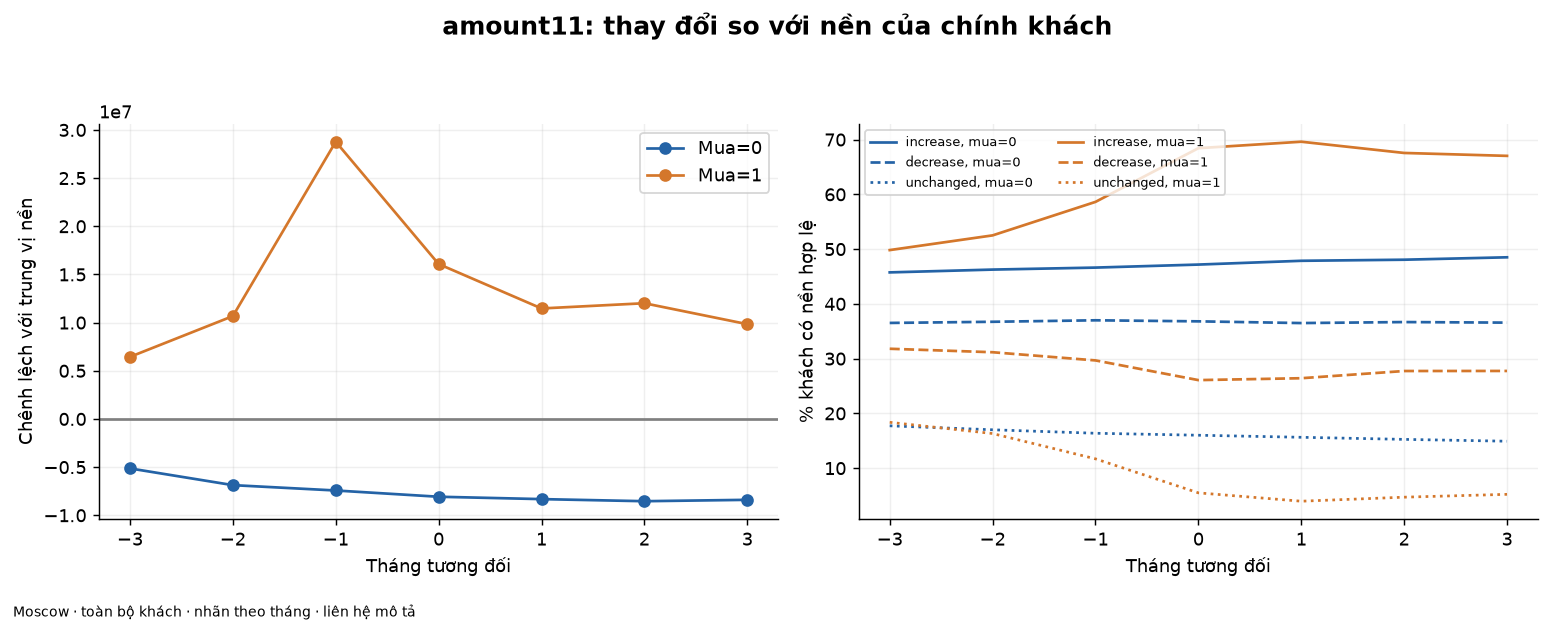

**outputs/eda_figures_moscow/baseline_dialog.png**

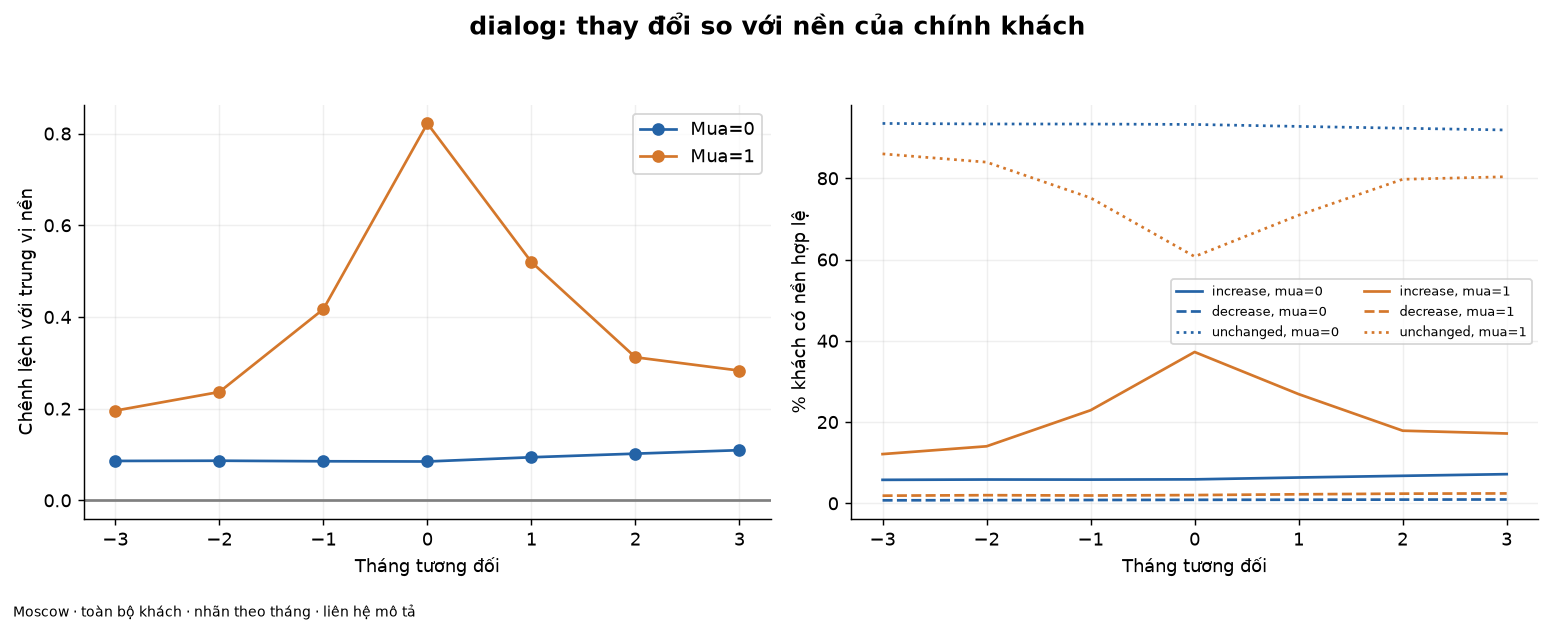

**outputs/eda_figures_moscow/baseline_geo.png**

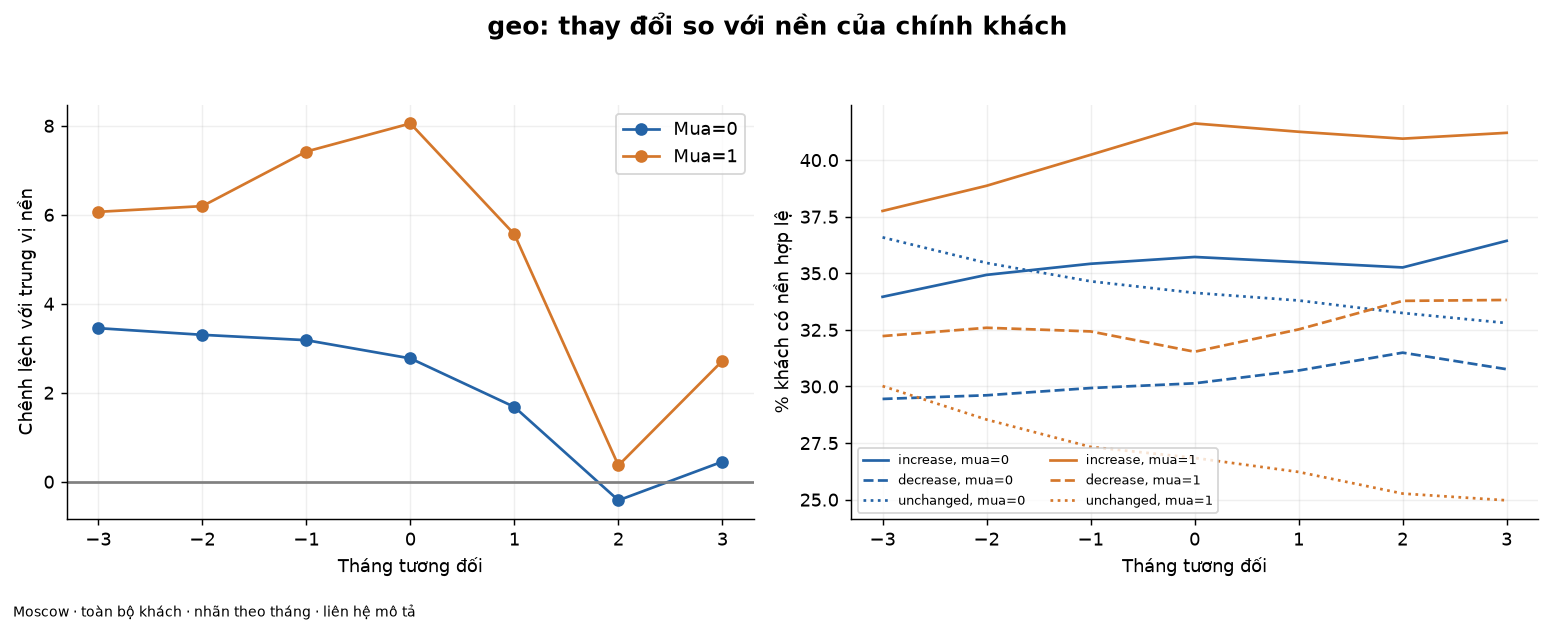

**outputs/eda_figures_moscow/baseline_trx.png**

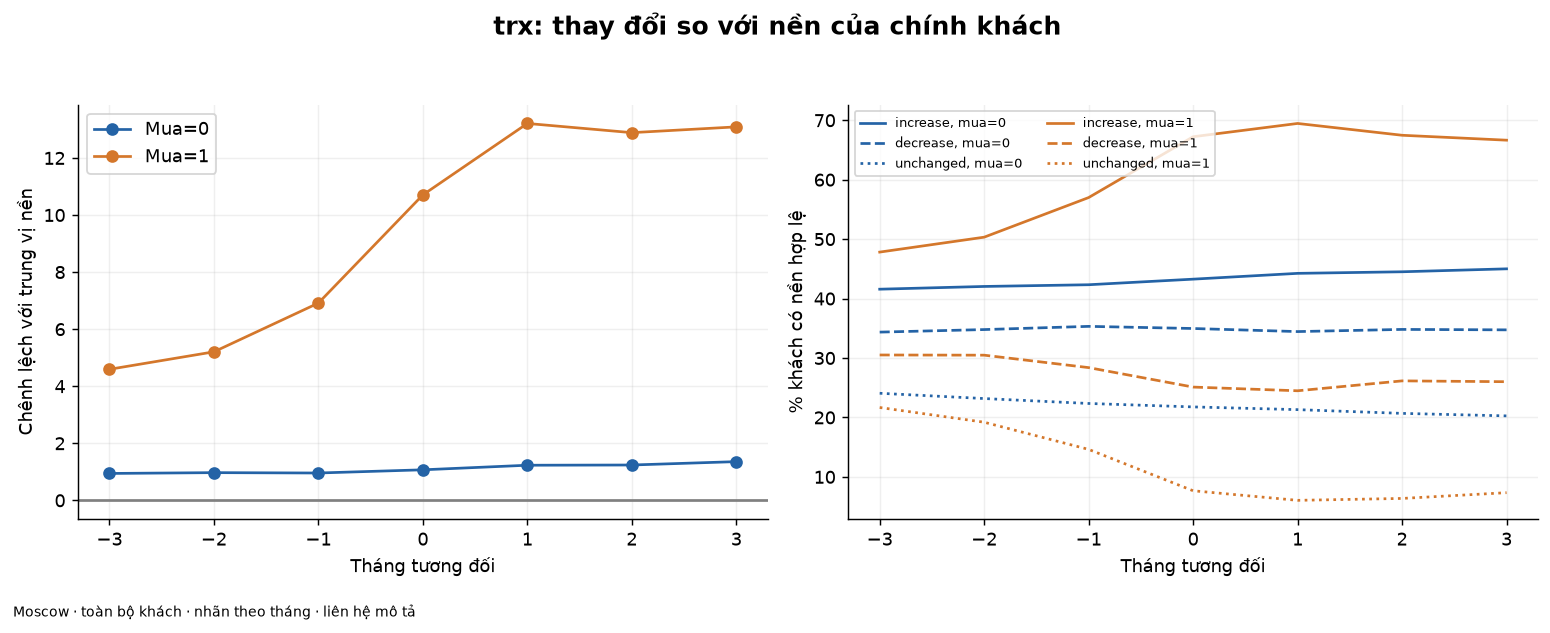

**outputs/eda_figures_moscow/composition_amount11.png**

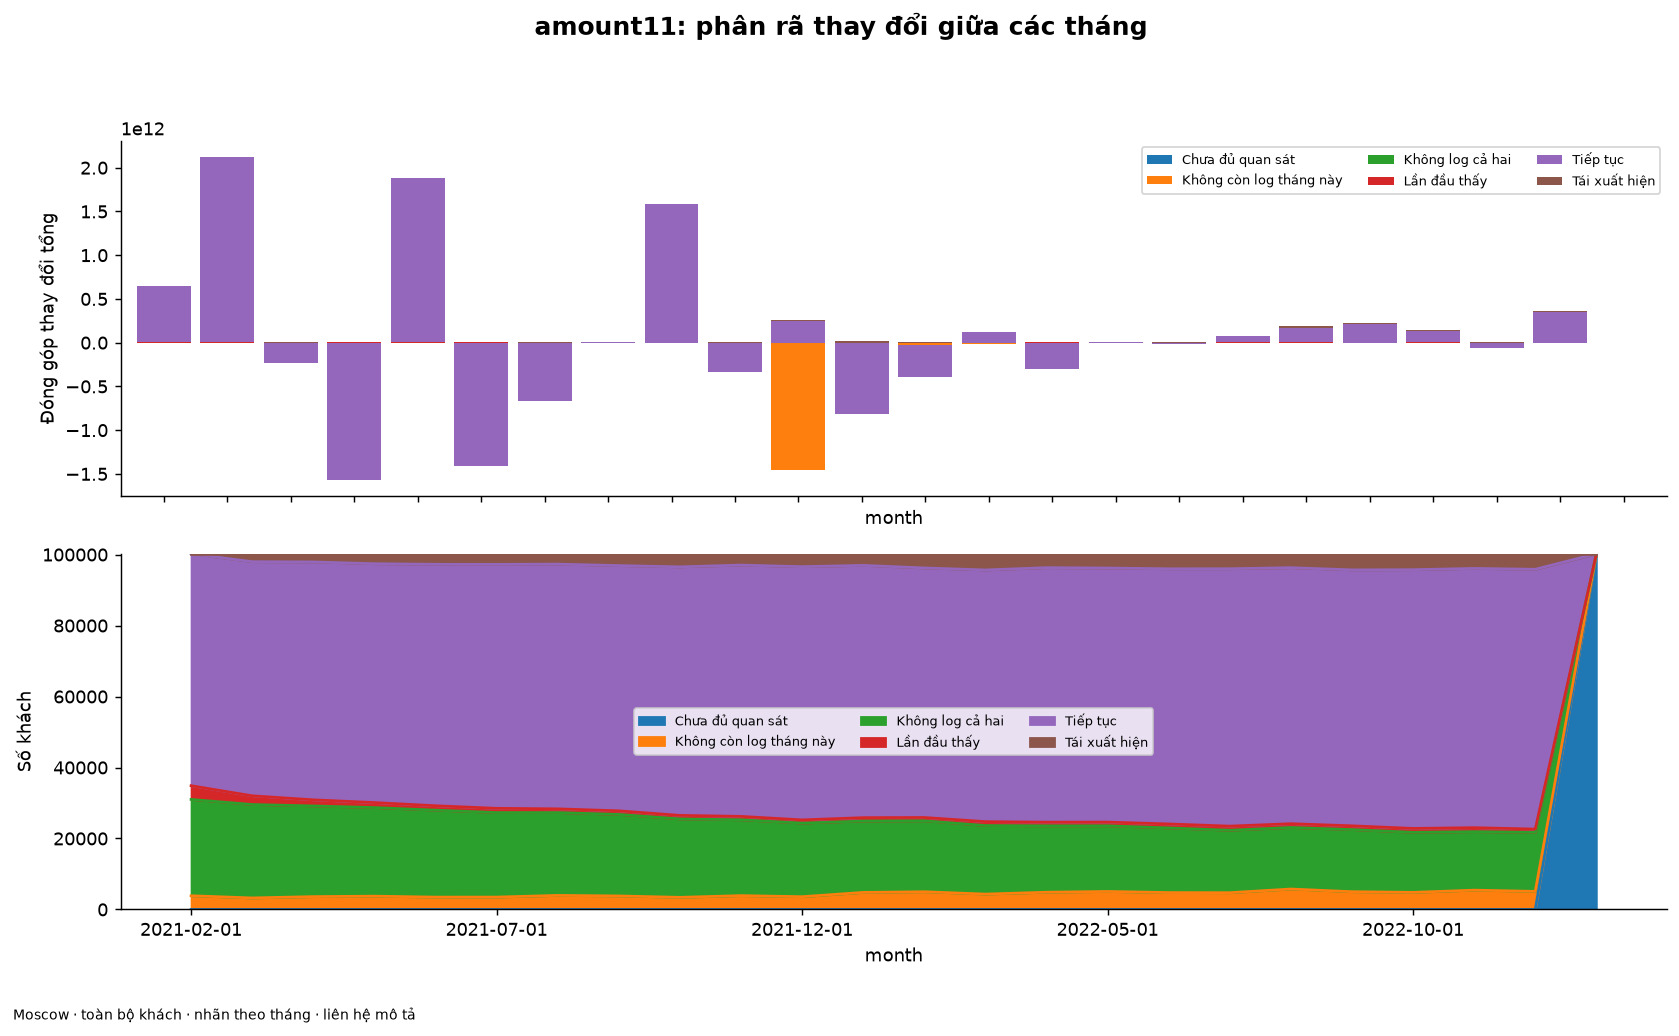

**outputs/eda_figures_moscow/composition_dialog.png**

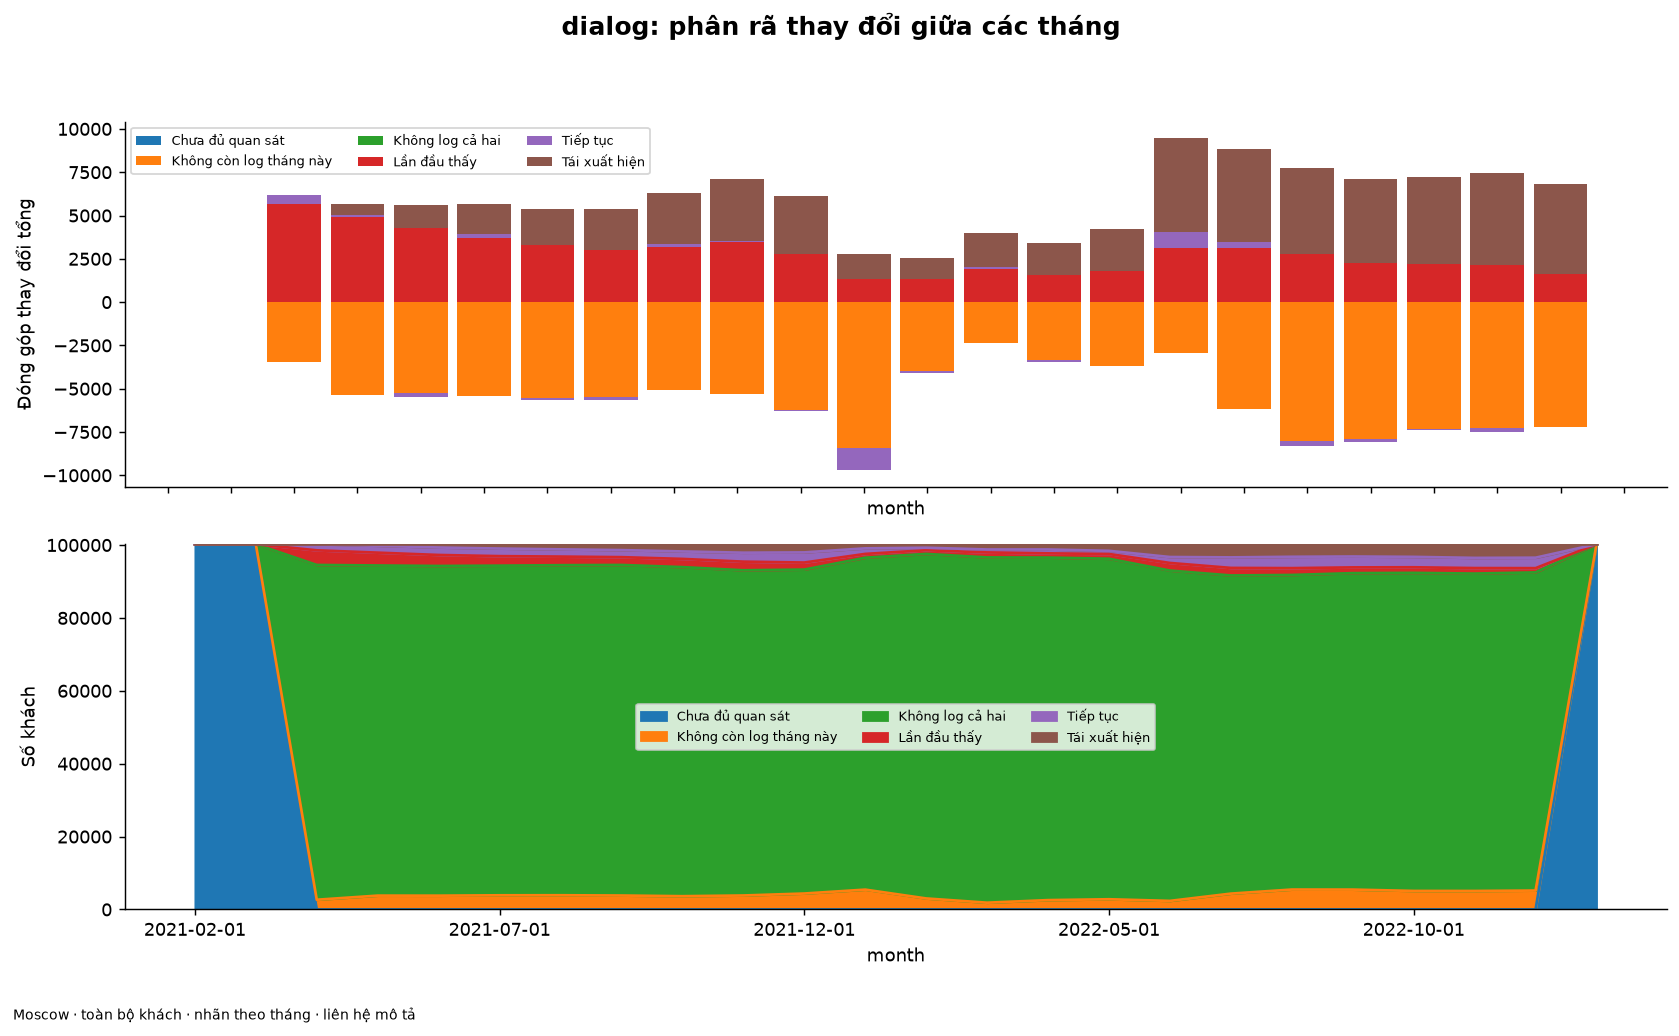

**outputs/eda_figures_moscow/composition_geo.png**

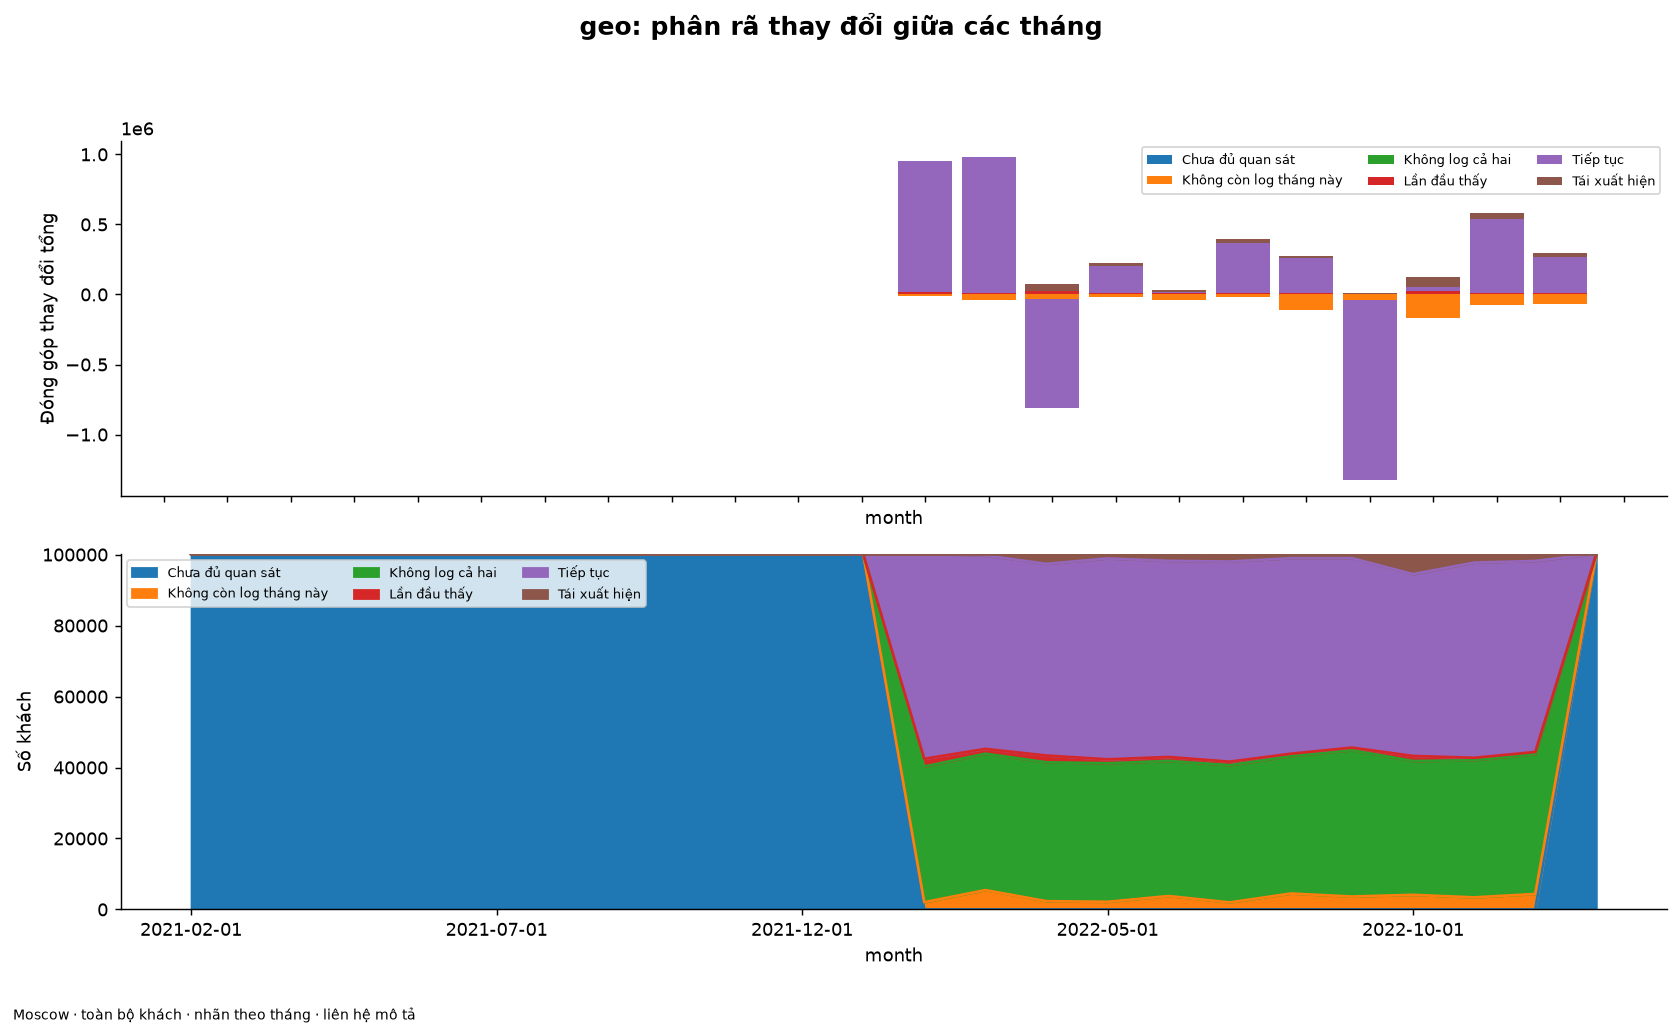

**outputs/eda_figures_moscow/composition_trx.png**

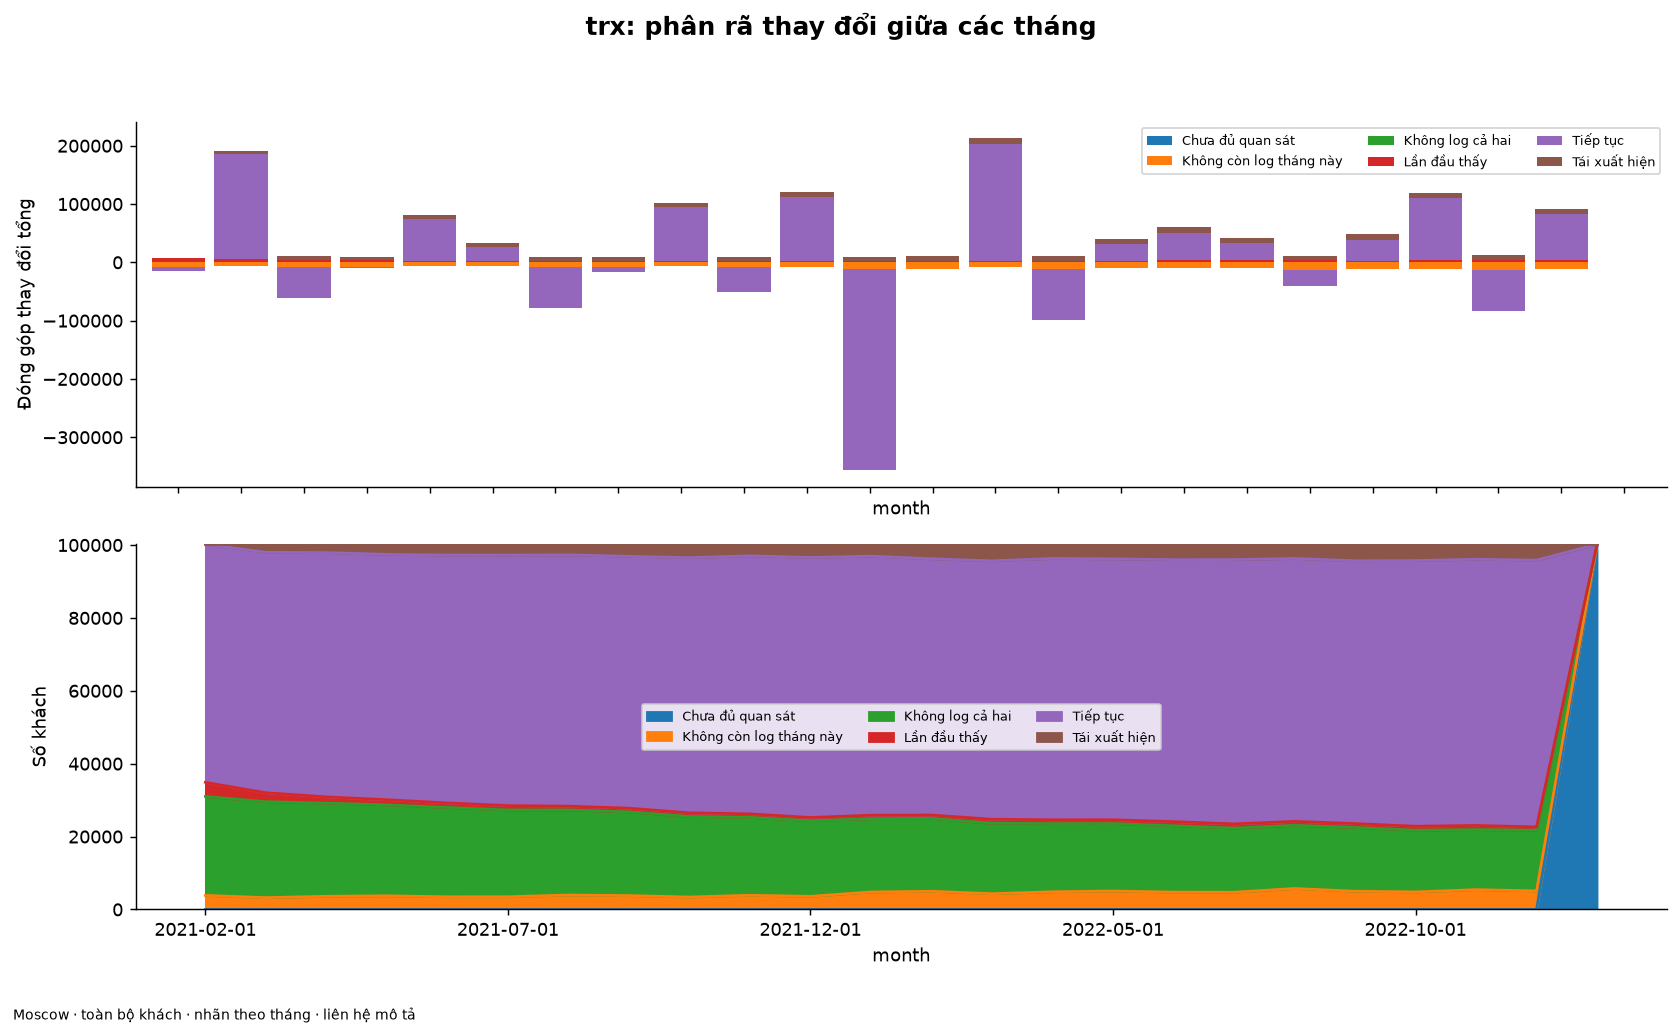

**outputs/eda_figures_moscow/event_amount11.png**

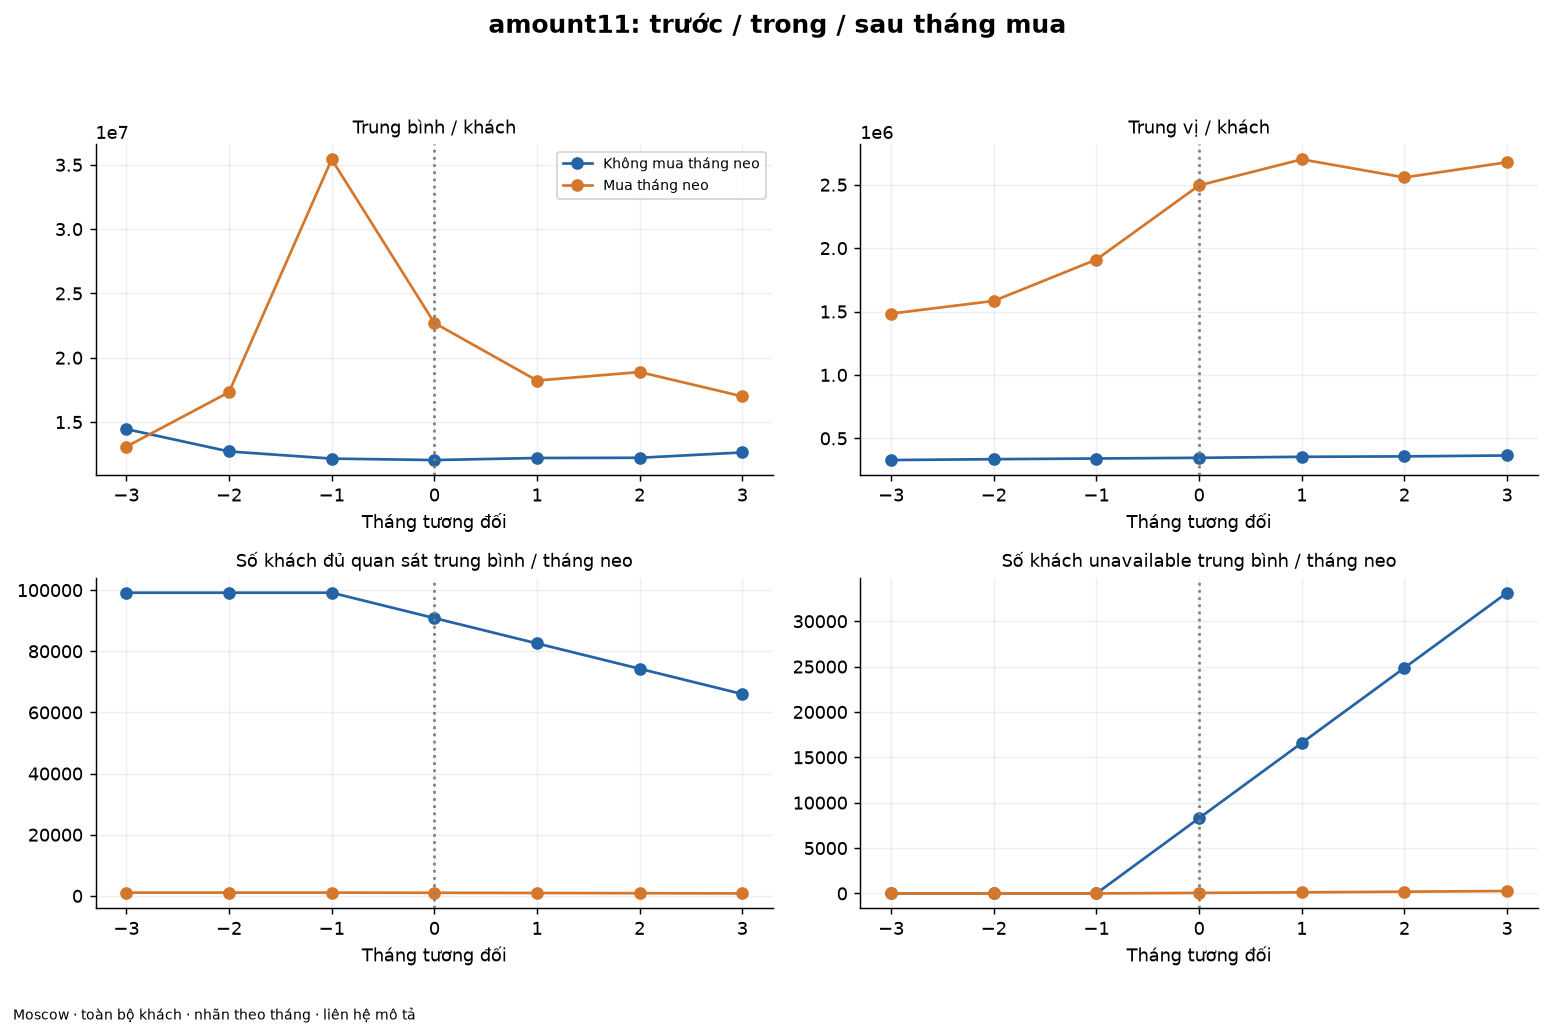

**outputs/eda_figures_moscow/event_amount11_by_anchor.png**

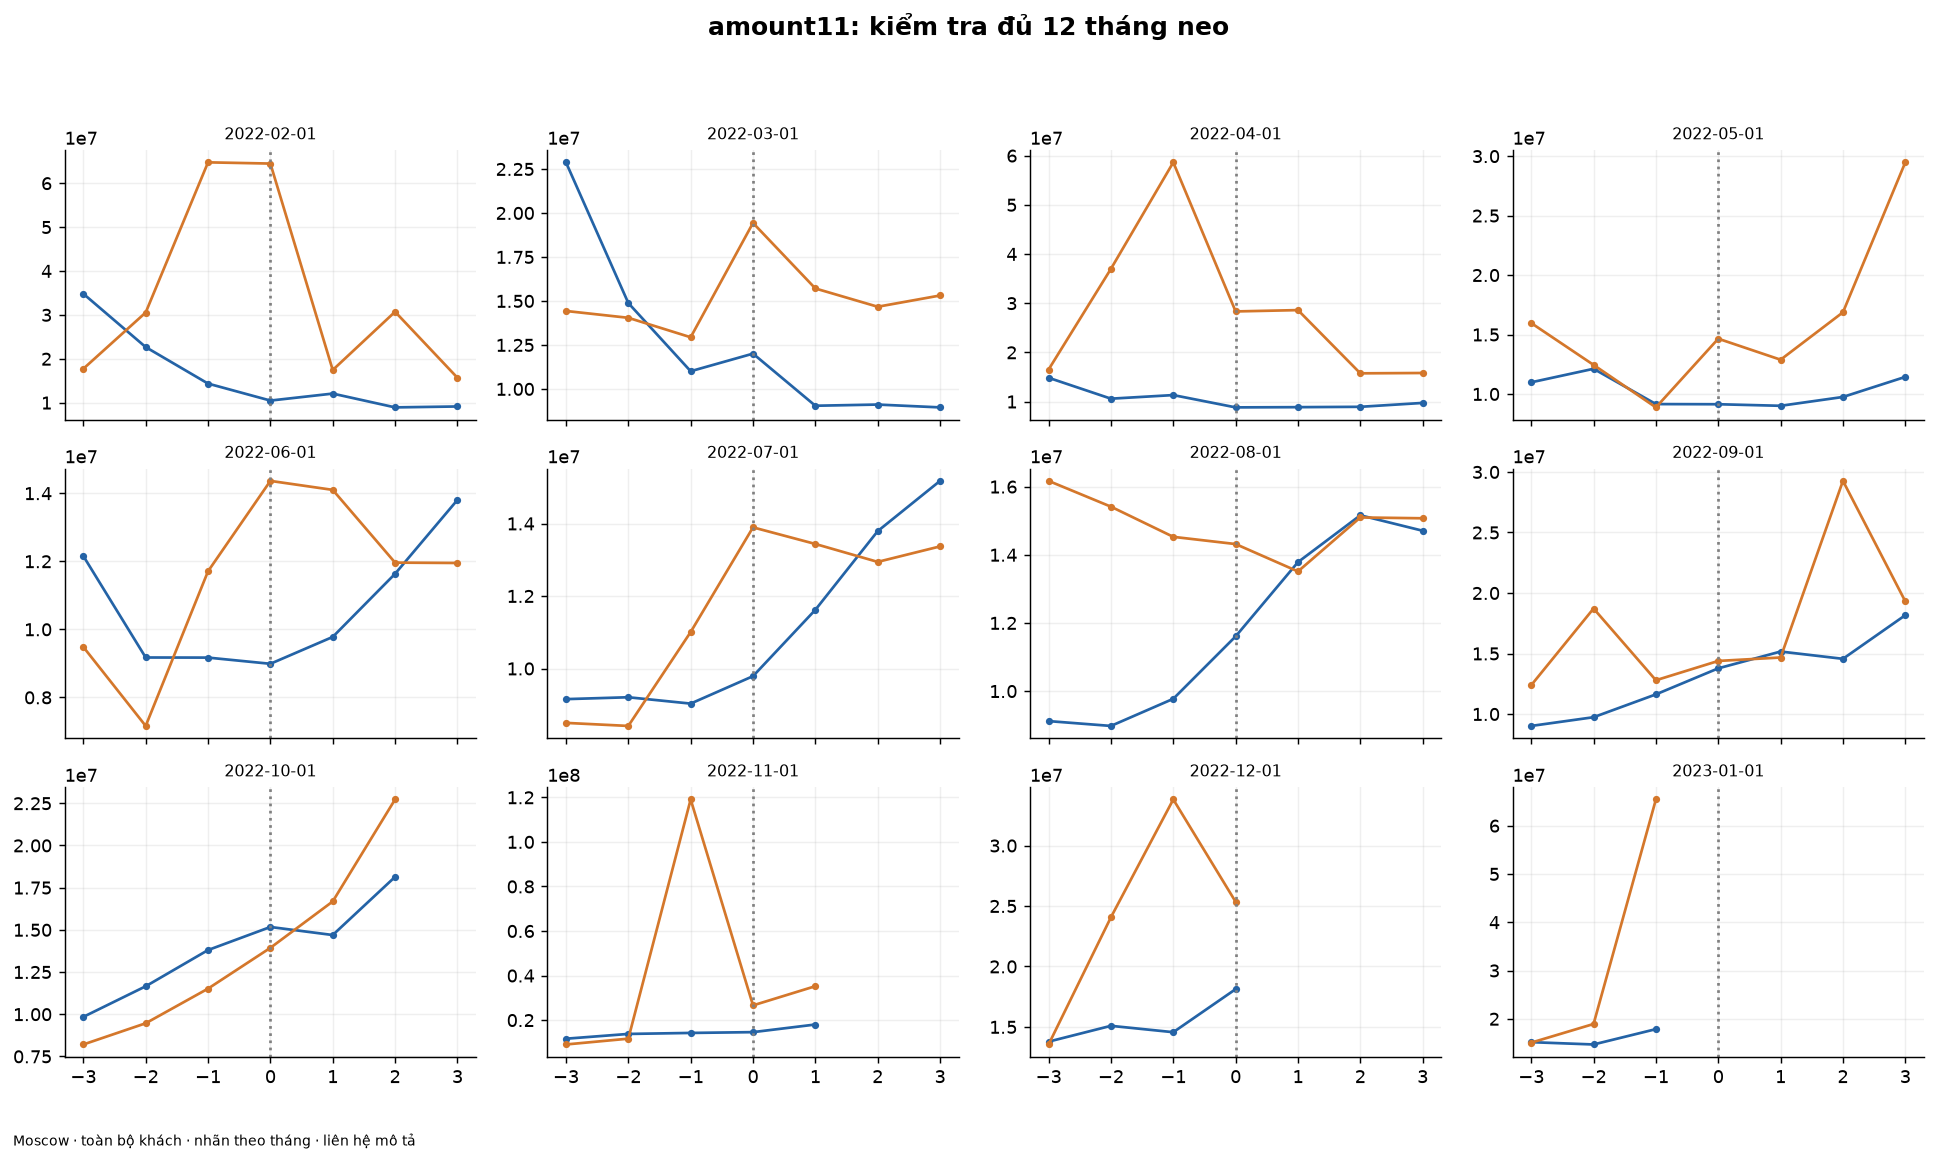

**outputs/eda_figures_moscow/event_dialog.png**

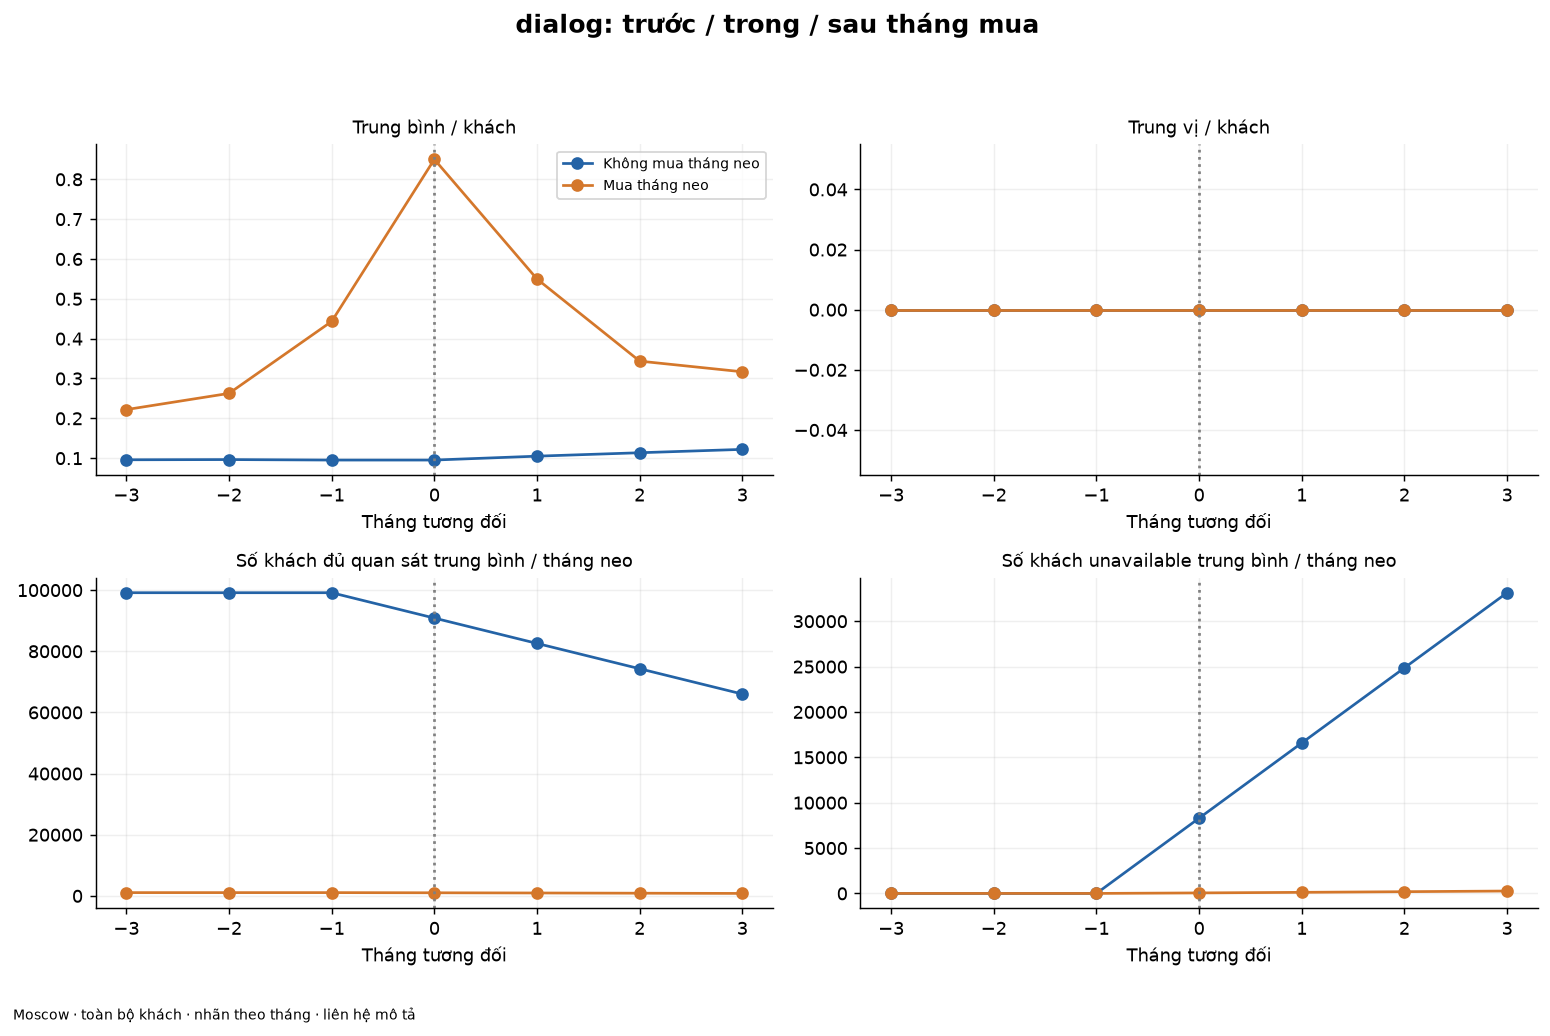

**outputs/eda_figures_moscow/event_dialog_by_anchor.png**

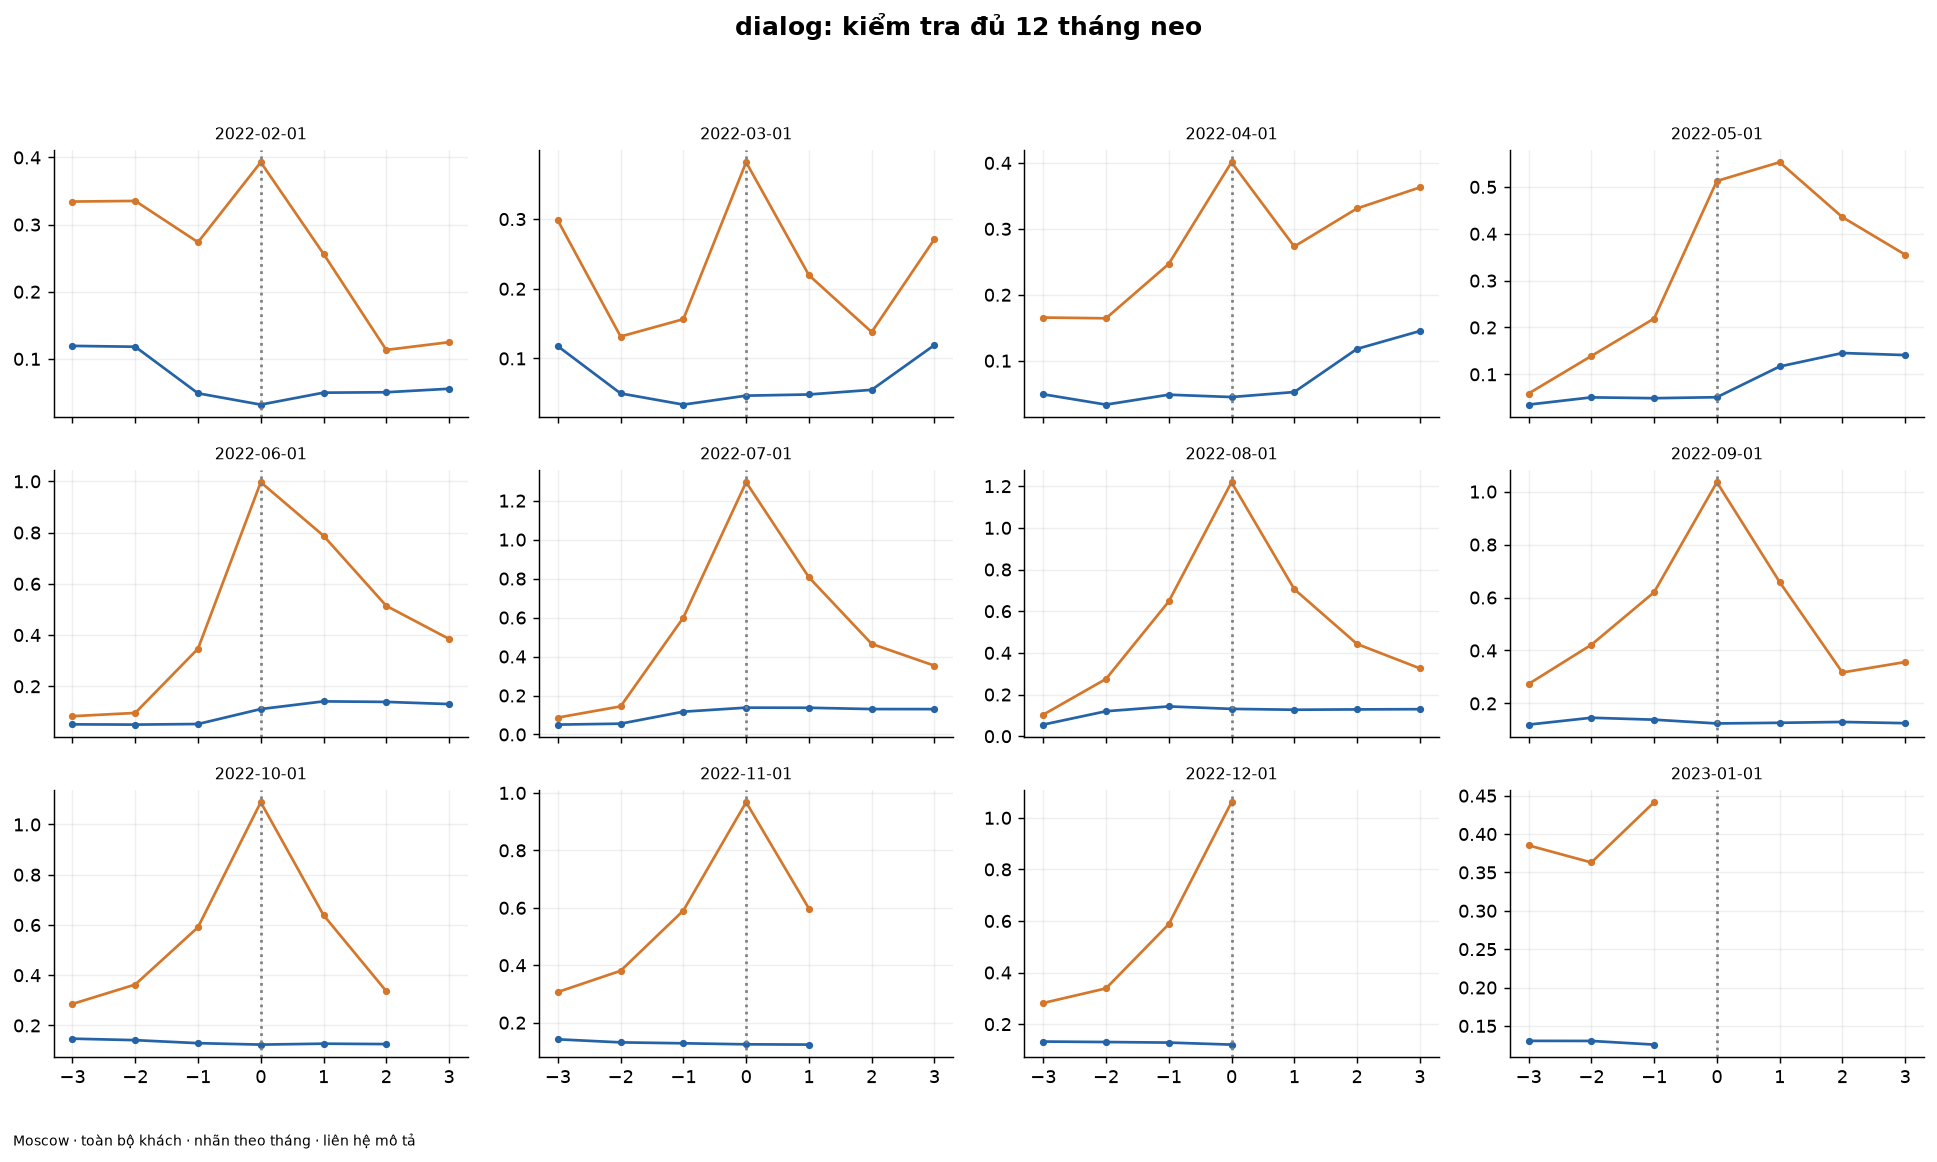

**outputs/eda_figures_moscow/event_geo.png**

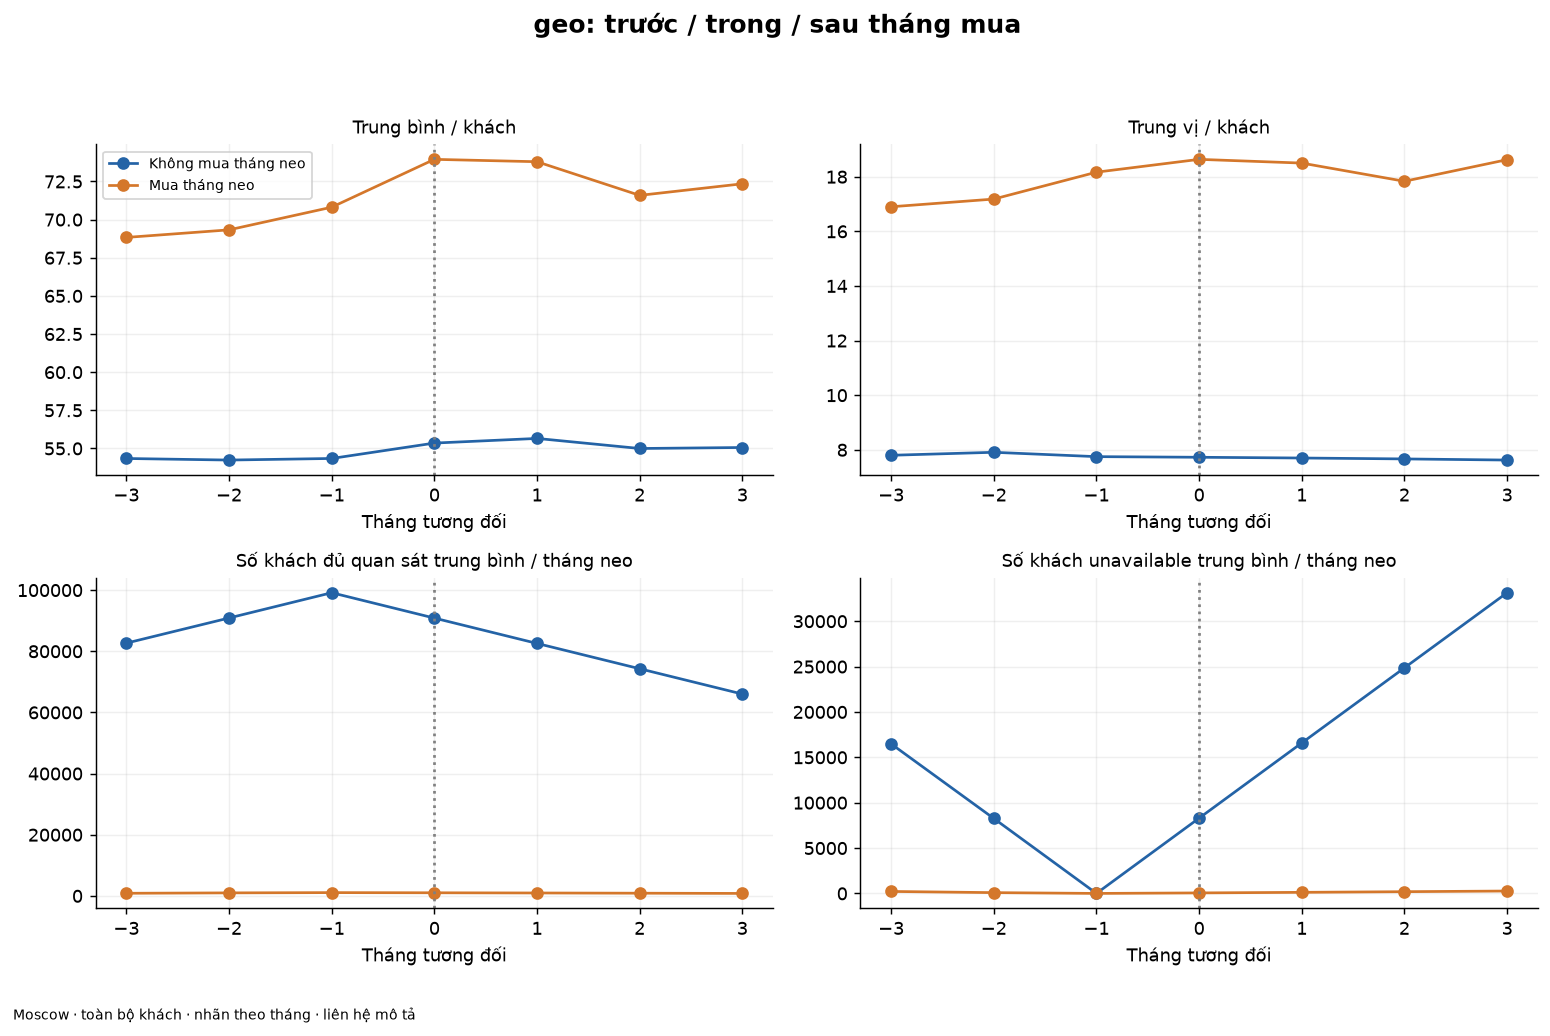

**outputs/eda_figures_moscow/event_geo_by_anchor.png**

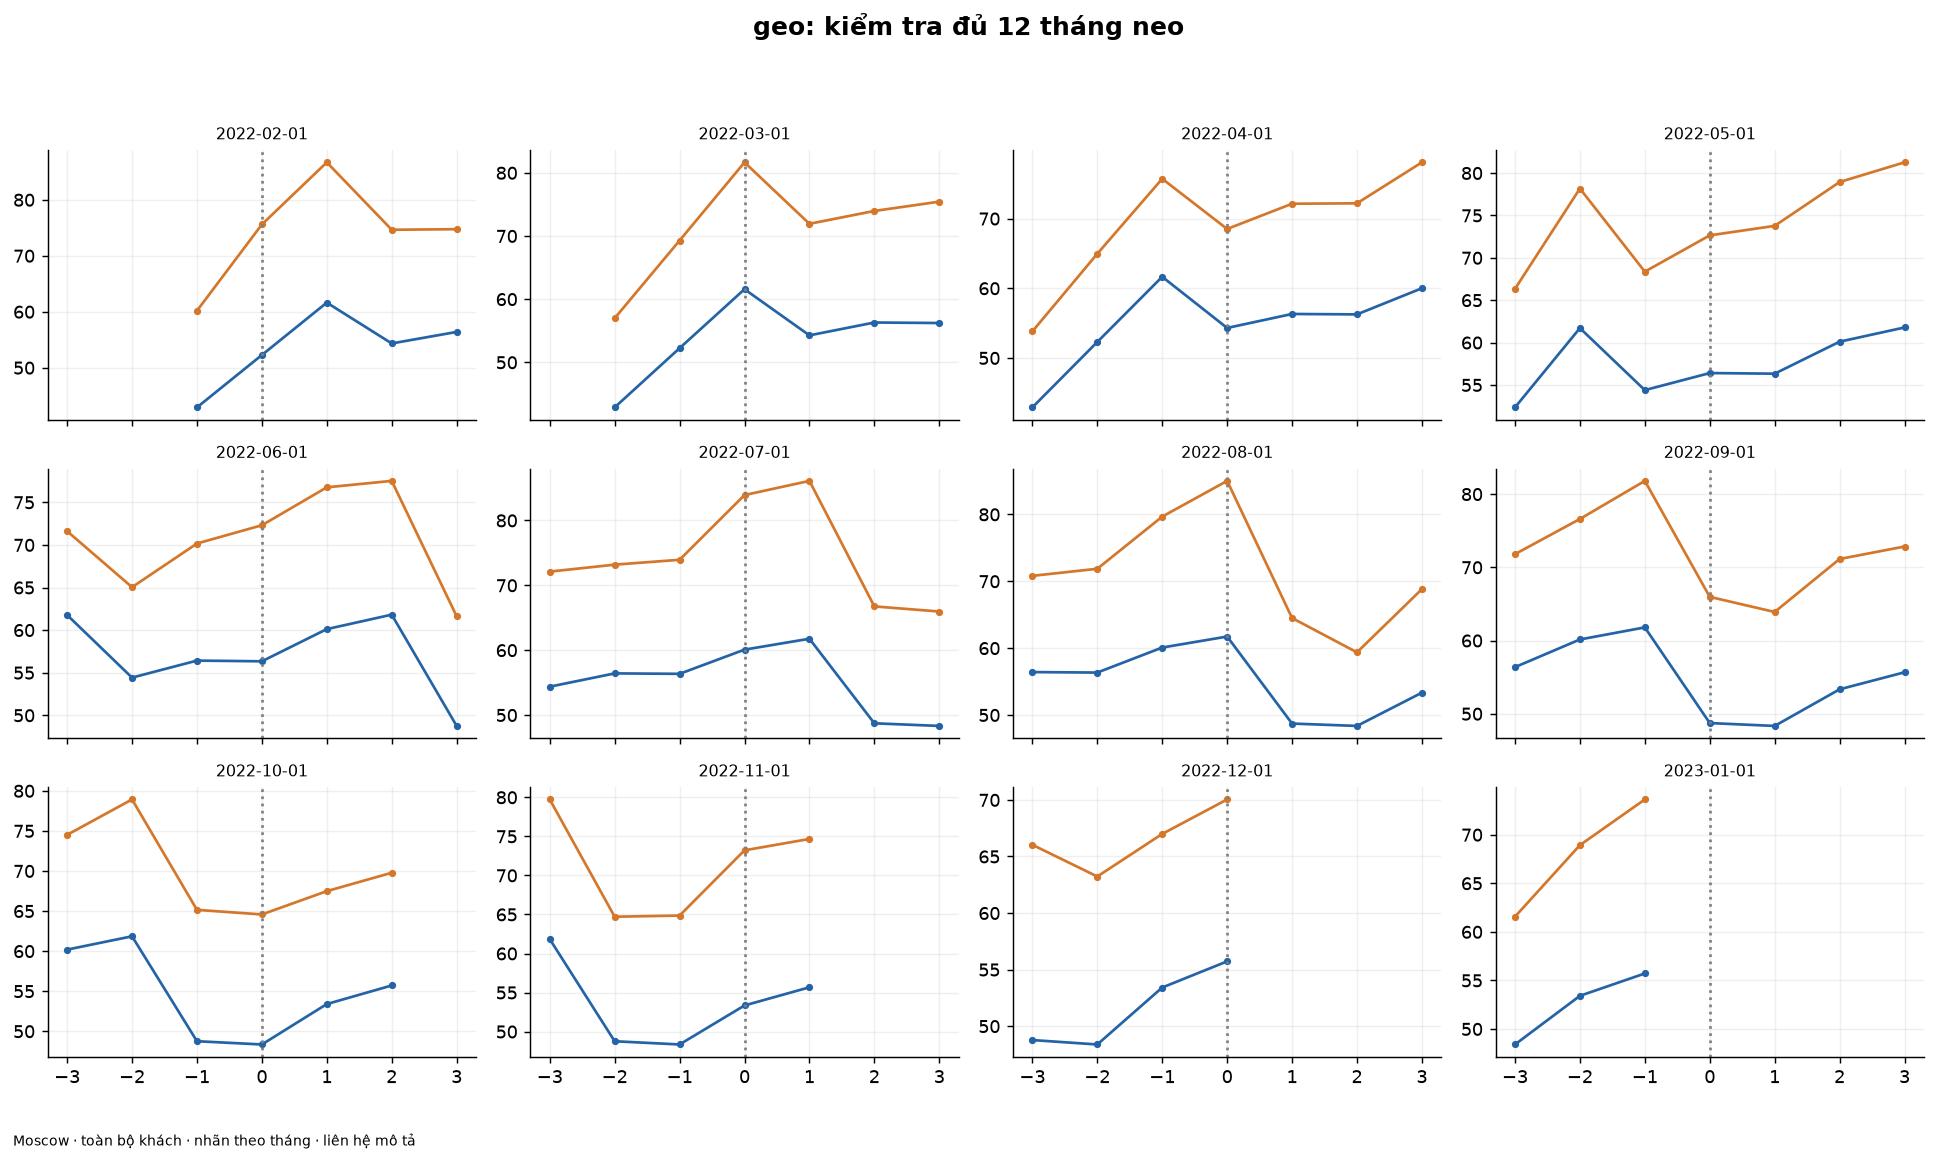

**outputs/eda_figures_moscow/event_trx.png**

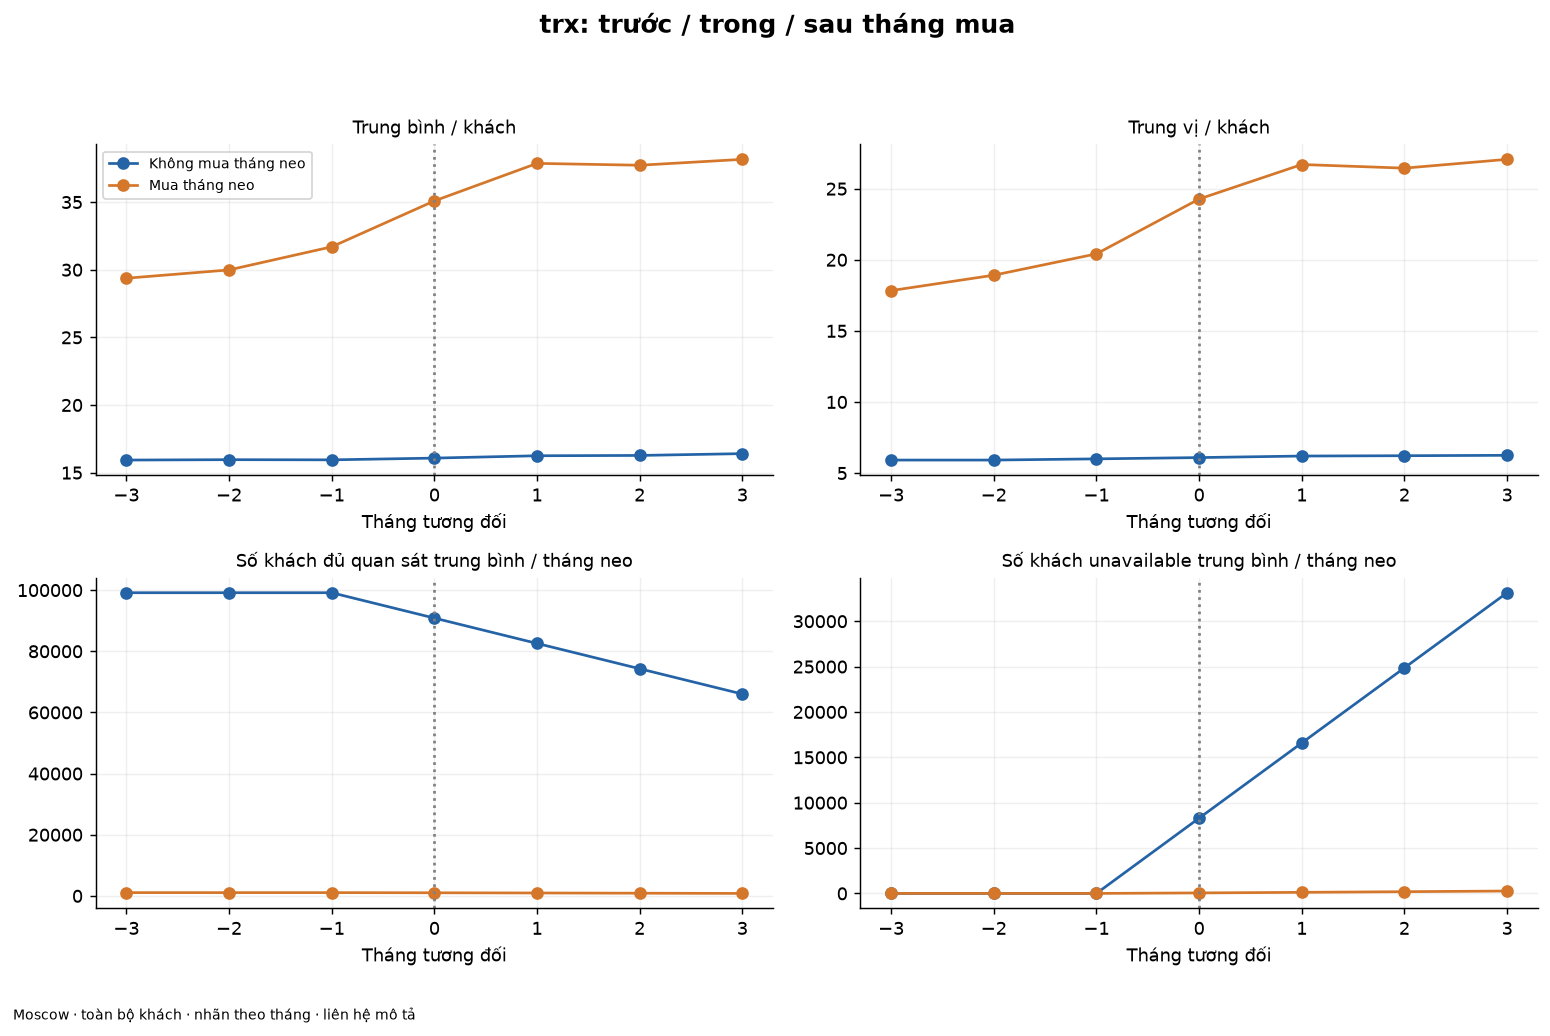

**outputs/eda_figures_moscow/event_trx_by_anchor.png**

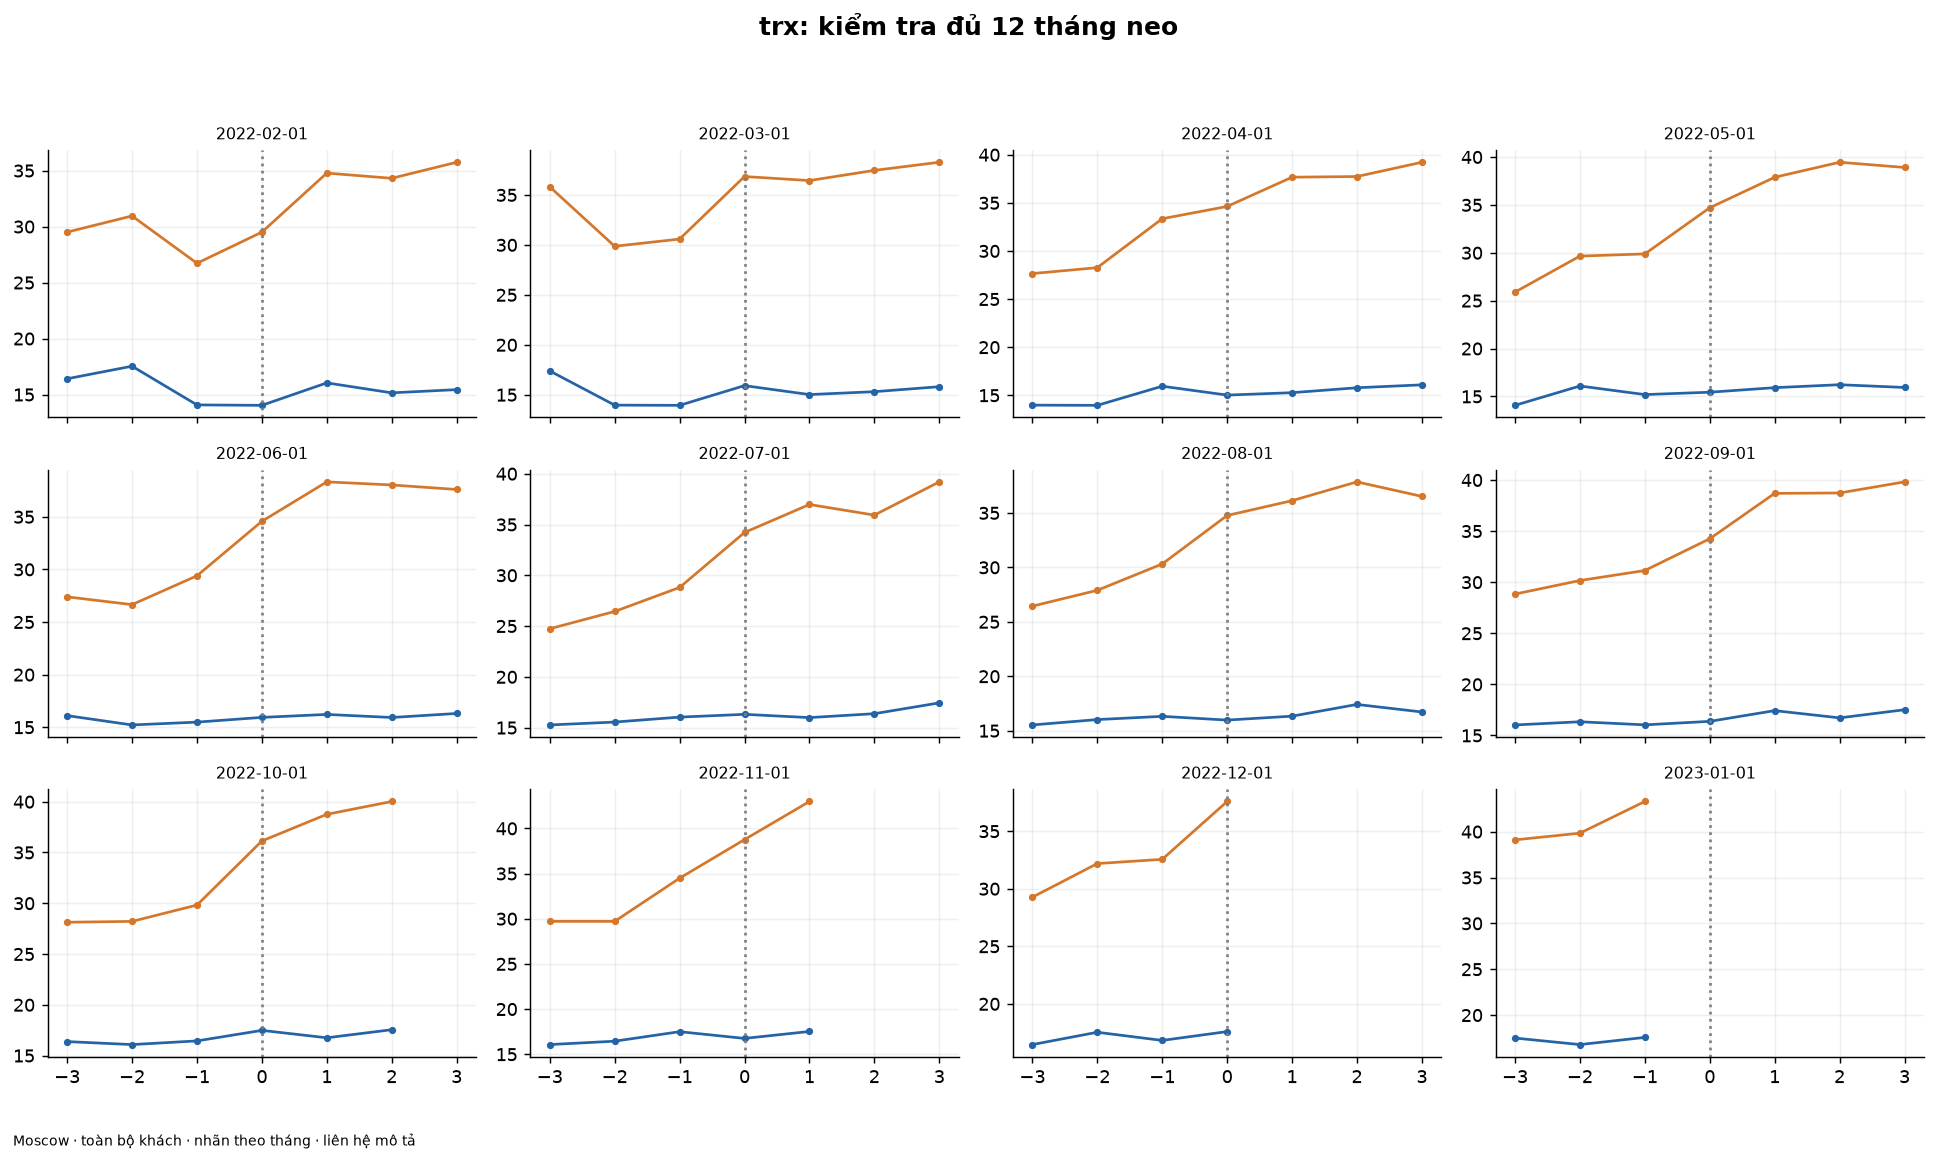

**outputs/eda_figures_moscow/source_combinations_monthly.png**

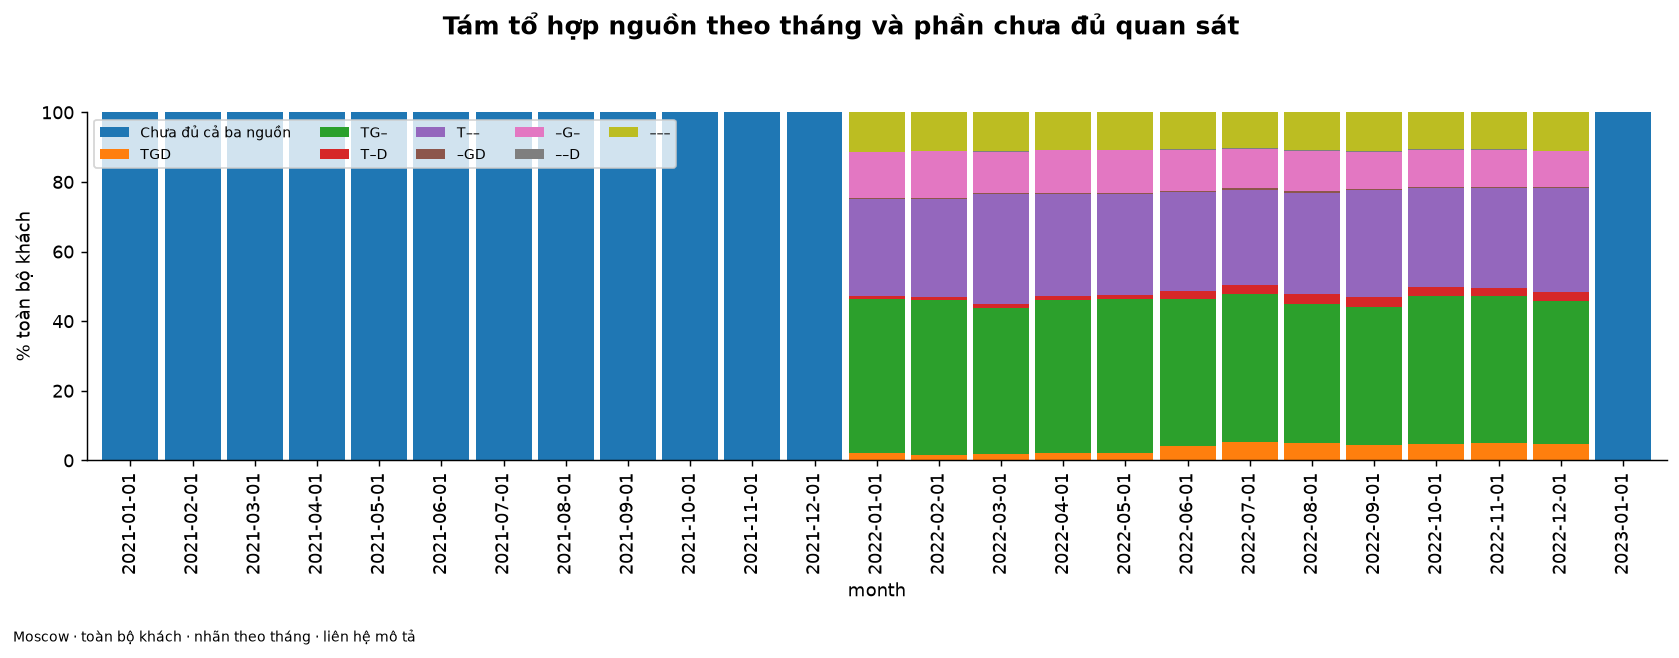

**outputs/eda_figures_moscow/baseline_amount11.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,amount11,2022-02-01,-3,0,99183,99183,0,3.481506e+07,3.151739e+05,99183,0,15864,26255,1.253827e+07,0.443372,0.347348,0.209280
1,amount11,2022-02-01,-3,1,1041,1041,0,1.772617e+07,1.319837e+06,1041,0,186,270,1.004008e+07,0.522574,0.290106,0.187320
2,amount11,2022-02-01,-2,0,99183,99183,0,2.266500e+07,3.708423e+05,99183,0,15864,26255,3.882124e+05,0.491657,0.308077,0.200266
3,amount11,2022-02-01,-2,1,1041,1041,0,3.053932e+07,1.590490e+06,1041,0,186,270,2.285322e+07,0.556196,0.273775,0.170029
4,amount11,2022-02-01,-1,0,99183,99183,0,1.434577e+07,2.584400e+05,99183,0,15864,26255,-7.931021e+06,0.408366,0.395118,0.196516


**outputs/eda_figures_moscow/baseline_dialog.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,dialog,2022-02-01,-3,0,99183,99183,0,0.119345,0.0,99183,0,75414,96820,0.098343,0.067451,0.015194,0.917355
1,dialog,2022-02-01,-3,1,1041,1041,0,0.334294,0.0,1041,0,562,968,0.273775,0.168108,0.031700,0.800192
2,dialog,2022-02-01,-2,0,99183,99183,0,0.118095,0.0,99183,0,75414,96820,0.097093,0.065818,0.016485,0.917698
3,dialog,2022-02-01,-2,1,1041,1041,0,0.335255,0.0,1041,0,562,968,0.274736,0.175793,0.047070,0.777137
4,dialog,2022-02-01,-1,0,99183,99183,0,0.048728,0.0,99183,0,75414,96820,0.027727,0.034028,0.020830,0.945142


**outputs/eda_figures_moscow/baseline_geo.csv** — 5 dòng đầu

,metric,anchor,lag,purchase,population,observed,unavailable,mean,median,baseline_eligible,baseline_insufficient,baseline_unseen,baseline_zero,delta_mean,increase,decrease,unchanged
0,geo,2022-02-01,-3,0,99183,0,99183,NaN,NaN,0,99183,0,0,NaN,NaN,NaN,NaN
1,geo,2022-02-01,-3,1,1041,0,1041,NaN,NaN,0,1041,0,0,NaN,NaN,NaN,NaN
2,geo,2022-02-01,-2,0,99183,0,99183,NaN,NaN,0,99183,0,0,NaN,NaN,NaN,NaN
3,geo,2022-02-01,-2,1,1041,0,1041,NaN,NaN,0,1041,0,0,NaN,NaN,NaN,NaN
4,geo,2022-02-01,-1,0,99183,99183,0,42.911164,8.0,0,99183,0,0,NaN,NaN,NaN,NaN


... (27 outputs left out)

,figure,title,data,explanation
0,source_combinations_monthly,Tám tổ hợp nguồn theo tháng và phần chưa đủ qu...,source_combinations_monthly.csv,source_combinations_monthly.md
1,event_trx,trx: trước / trong / sau tháng mua,event_trx.csv,event_trx.md
2,event_trx_by_anchor,trx: kiểm tra đủ 12 tháng neo,event_trx_by_anchor.csv,event_trx_by_anchor.md
3,baseline_trx,trx: thay đổi so với nền của chính khách,baseline_trx.csv,baseline_trx.md
4,event_geo,geo: trước / trong / sau tháng mua,event_geo.csv,event_geo.md


**outputs/eda_figures_moscow/source_combinations_monthly.csv** — 5 dòng đầu

,month,group,customers
0,2021-01-01,Chưa đủ cả ba nguồn,100224
1,2021-02-01,Chưa đủ cả ba nguồn,100224
2,2021-03-01,Chưa đủ cả ba nguồn,100224
3,2021-04-01,Chưa đủ cả ba nguồn,100224
4,2021-05-01,Chưa đủ cả ba nguồn,100224


File kết quả khác: `outputs/eda_figures_moscow/INDEX.md`, `outputs/eda_figures_moscow/baseline_amount11.md`, `outputs/eda_figures_moscow/baseline_dialog.md`, `outputs/eda_figures_moscow/baseline_geo.md`, `outputs/eda_figures_moscow/baseline_trx.md`, `outputs/eda_figures_moscow/composition_amount11.md`, `outputs/eda_figures_moscow/composition_dialog.md`, `outputs/eda_figures_moscow/composition_geo.md`, `outputs/eda_figures_moscow/composition_trx.md`, `outputs/eda_figures_moscow/event_amount11.md`, `outputs/eda_figures_moscow/event_amount11_by_anchor.md`, `outputs/eda_figures_moscow/event_dialog.md`, `outputs/eda_figures_moscow/event_dialog_by_anchor.md`, `outputs/eda_figures_moscow/event_geo.md`, `outputs/eda_figures_moscow/event_geo_by_anchor.md`, `outputs/eda_figures_moscow/event_trx.md`, `outputs/eda_figures_moscow/event_trx_by_anchor.md`, `outputs/eda_figures_moscow/execution_status.json`, `outputs/eda_figures_moscow/source_combinations_monthly.md`

In [6]:
show_generated_results(__eda_started_ns, 'src/scripts/complete_eda_figures_moscow.py')